# Swiss roll: FEM (RFM reference code) vs. kernel-graph Nyström spectral distances

**Question.** The RFM reference code (Chen & Lipman, ICLR 2024; `facebookresearch/riemannian-fm`, `manifm/manifolds/mesh.py`) discretizes the Laplace–Beltrami operator with linear finite elements on a triangle mesh. `riemannian_swiss_roll_toy_example.ipynb` instead builds a kernel graph on 5,000 uniform samples and extends its Laplacian eigenvectors with Nyström. Both feed the same 32-mode biharmonic distance into the same RFM field
$$u_t(x\mid x_1)=-\frac{d(x,x_1)}{1-t}\,\frac{\nabla d(x,x_1)}{\|\nabla d(x,x_1)\|^2}.$$
This notebook compares the two discretizations on the swiss roll, step by step, and then trains CellFlow RFM with each.

| | FEM, as in the RFM code | Kernel graph + Nyström (this repository) |
| --- | --- | --- |
| Geometry | triangle mesh | 5,000 uniform construction points |
| Operator | $L=-$`cotmatrix`, lumped mixed-Voronoi mass $M$; $L\phi=\lambda M\phi$ | $W$ from `SymmetricBandwidthKernel` ($k_\rho=24$, $\delta=2$); $L=D-W$; $L\phi=\lambda\phi$ |
| Normalization | $\phi^\top M\phi=I$ (area $L^2$) | $\phi^\top\phi=I$ |
| Between nodes | barycentric interpolation in the closest triangle | $\Psi_\ell(x)=a_\ell\sum_j w_j(x)\phi_{j\ell}/(d(x)-\lambda_\ell)$ |
| $\nabla d$ | autodiff; constant per triangle | analytic; ambient, smooth inside the kernel support |

**Premetrics compared** (all 32 non-constant modes, biharmonic weights $1/\lambda$ on the coordinates):

| Name | Construction |
| --- | --- |
| **reference** | FEM on a structured strip mesh with $h=0.006$ (303k vertices); its spectrum is converged to $\sim10^{-4}$ (checked against $h=0.012$). Stands in for the exact Laplace–Beltrami operator, which has no closed form on the roll. |
| **FEM, Delaunay** | The RFM recipe applied to *your* data: Delaunay triangulation of the same 5,000 construction points, restricted to the roll; closest-triangle search over all faces as in `manifm`. |
| **FEM, structured** | The RFM recipe on a good mesh of the same size: structured strip mesh, 4,693 vertices. |
| **fixed Gaussian**, **variable Gaussian**, … | Your kernel profiles from `riemannian_toys.kernels`, fitted exactly as in the swiss roll notebook. The fixed Gaussian is the one that notebook trains with. |

**Implementation notes.** `riemannian_toys.fem` re-implements libigl's `cotmatrix` and `massmatrix(VORONOI)` (libigl is not installed in the container), solves with `eigsh(L, 33, M, sigma=0, which="LM")` as the reference code does, and wraps the result in `FEMPremetric`, which has the interface of `SpectralNystroem`. RFM training, the interpolators and the toy helpers therefore use it unchanged. JAX runs in float32, as in the other notebooks.

**The summary of the results is in section 11.**

**Contents.** 1 data and fits · 2 meshes · 3 spectrum · 4 eigenfunctions · 5 distances and OT couplings · 6 conditional fields · 7 conditional Euler paths · 8 reference paths vs. geodesics and regression targets · 9 cost · 10 training CellFlow RFM with each premetric (3 seeds) · 11 summary.

In [1]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # share the GPU with other kernels
os.environ.setdefault("TQDM_DISABLE", "1")                         # no per-iteration progress bars in the saved notebook

import json
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd
from IPython.display import display
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

from cellflow.ode_solver import RFMInterpolation
from riemannian_toys import fem, flows, intermediate, kernels, plotting, reference_paths
from riemannian_toys.swiss_roll import SwissRoll

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

n_modes = 32
kernel_settings = {"density_k": 24, "delta": 2.0, "n_modes": n_modes, "laplacian_type": "unnormalized",
                   "spectral_weight_type": "biharmonic"}
training_solver_kwargs = {"interpolation_steps": 32, "project_to_manifold": False, "max_velocity_norm": 30.0}
print("JAX", jax.__version__, jax.devices())

JAX 0.12.1 [CudaDevice(id=0)]


## 1 · Data and kernel fits

Same roll, construction points (seed 42), Gaussian clouds (seed 123) and kernel settings as `riemannian_swiss_roll_toy_example.ipynb`. The outer-end Gaussian is the source, the inner-end Gaussian the target.

In [2]:
roll = SwissRoll(inner_radius=1.0, pitch=1.2, half_width=0.3, turns=1.5)
points = roll.sample_uniform(5_000, np.random.default_rng(42))
construction_points = points.astype(np.float32)

rng = np.random.default_rng(123)
variance, n_points_per_gaussian, end_offset = 0.09, 250, 1.2
mean_outer = roll.strip_point(roll.theta_at_arc_length(roll.centerline_length - end_offset))
mean_inner = roll.strip_point(roll.theta_at_arc_length(end_offset))
outer_window, inner_window = (roll.theta_max - np.pi, roll.theta_max), (0.0, np.pi)
outer_gaussian_points = roll.sample_gaussian(mean_outer, variance, n_points_per_gaussian, rng, theta_window=outer_window)[0]
inner_gaussian_points = roll.sample_gaussian(mean_inner, variance, n_points_per_gaussian, rng, theta_window=inner_window)[0]
source, target = outer_gaussian_points.astype(np.float32), inner_gaussian_points.astype(np.float32)
field_target = mean_inner.astype(np.float32)   # the notebook's `kernel_target`

kernel_models, kernel_fitted, kernel_graphs, kernel_fit_df = kernels.fit_kernel_profiles(
    construction_points, kernels.KERNEL_PROFILES, **kernel_settings)
display(kernel_fit_df[["edges", "min_degree", "median_degree", "lambda_2", "fit_seconds"]])

fixed Gaussian: fitted in 1.42s


variable Gaussian: fitted in 0.57s


compact polynomial: fitted in 0.71s


smooth bump: fitted in 0.68s


binary CkNN: fitted in 0.61s


,edges,min_degree,median_degree,lambda_2,fit_seconds
kernel,,,,,
fixed Gaussian,211020,7.837295,22.508794,0.002460,1.423714
variable Gaussian,211020,38.941019,66.586388,0.017850,0.567096
compact polynomial,211020,10.962988,18.568033,0.001715,0.705034
smooth bump,209211,20.545028,36.709227,0.005398,0.676814
binary CkNN,211020,47.000000,83.000000,0.024589,0.609396


## 2 · Meshes and FEM fits

* **FEM, Delaunay**: `scipy.spatial.Delaunay` on the 5,000 construction points. A triangle is kept if its edges are shorter than 0.3 (half the 0.6 gap between turns) and its centroid and edge midpoints lie within 0.01 of the roll. Every construction point stays a vertex, so the FEM eigenvectors live on exactly the same nodes as the kernel eigenvectors.
* **FEM, structured** and **reference**: vertices on a grid in strip coordinates (uniform in centerline arc length × uniform in radial offset), each cell split along its shorter diagonal.

The table checks that every mesh is a topological disc (Euler characteristic 1, one boundary loop, no non-manifold vertices), and that each solve converged ($\phi^\top M\phi=I$, residual of $L\phi=\lambda M\phi$).

In [3]:
mesh_vertices, mesh_faces, mesh_vertex_ids = fem.delaunay_domain_mesh(construction_points, roll.contains, max_edge=0.3)
assert np.array_equal(mesh_vertex_ids, np.arange(len(construction_points))), "every construction point must be a vertex"

def strip_factory(grid):
    return lambda vertices, faces: fem.strip_locator(roll, vertices, faces, grid)

fem_fits = {"FEM, Delaunay": fem.fit_fem(mesh_vertices, mesh_faces, n_modes, fem.brute_force_locator)}
for name, (n_along, n_across) in {"FEM, structured": (360, 12), "reference": (3000, 100), "reference, 2h": (1500, 50)}.items():
    vertices, faces, grid = fem.strip_mesh(roll, n_along, n_across)
    fem_fits[name] = fem.fit_fem(vertices, faces, n_modes, strip_factory(grid))

mesh_df = pd.DataFrame({name: {**fem.mesh_diagnostics(fit.vertices, fit.faces), **fit.diagnostics}
                        for name, fit in fem_fits.items()}).T
print(f"Exact strip area 2w * int r(theta) dtheta: "
      f"{2 * roll.half_width * (roll.inner_radius * roll.theta_max + roll.pitch * roll.theta_max**2 / (4 * np.pi)):.4f}")
display(mesh_df)

reference_error = np.abs(fem_fits["reference, 2h"].eigenvalues / fem_fits["reference"].eigenvalues - 1)
print(f"Reference spectrum, h=0.012 vs h=0.006: max relative eigenvalue change {reference_error.max():.2e} "
      f"(P1 error ~ h^2, so the h=0.006 error is about a third of that: {reference_error.max() / 3:.1e}).")

Exact strip area 2w * int r(theta) dtheta: 10.7442


,vertices,faces,euler_characteristic,boundary_loops,non_manifold_boundary_vertices,edges_in_more_than_two_faces,min_angle_deg,obtuse_face_fraction,area,eigsh_sigma,lambda_0,lambda_1,lambda_max,max_M_orthonormality_error,max_eigen_residual,fit_seconds
"FEM, Delaunay",5000.0,9726.0,1.0,1.0,0.0,0.0,0.037974,0.528069,10.328013,0.0,4.880331e-15,0.030972,29.417443,3.663736e-15,4.932111e-13,0.120973
"FEM, structured",4693.0,8640.0,1.0,1.0,0.0,0.0,39.876419,0.000000,10.742919,0.0,-1.583111e-15,0.030735,27.734007,2.886580e-15,1.867641e-13,0.097876
reference,303101.0,600000.0,1.0,1.0,0.0,0.0,40.208226,0.000000,10.744228,0.0,2.572451e-14,0.030725,27.887750,5.107026e-15,6.800288e-12,16.225406
"reference, 2h",76551.0,150000.0,1.0,1.0,0.0,0.0,40.163874,0.000000,10.744170,0.0,2.805480e-14,0.030725,27.880997,2.886580e-15,7.725818e-13,3.369958


Reference spectrum, h=0.012 vs h=0.006: max relative eigenvalue change 2.44e-04 (P1 error ~ h^2, so the h=0.006 error is about a third of that: 8.1e-05).


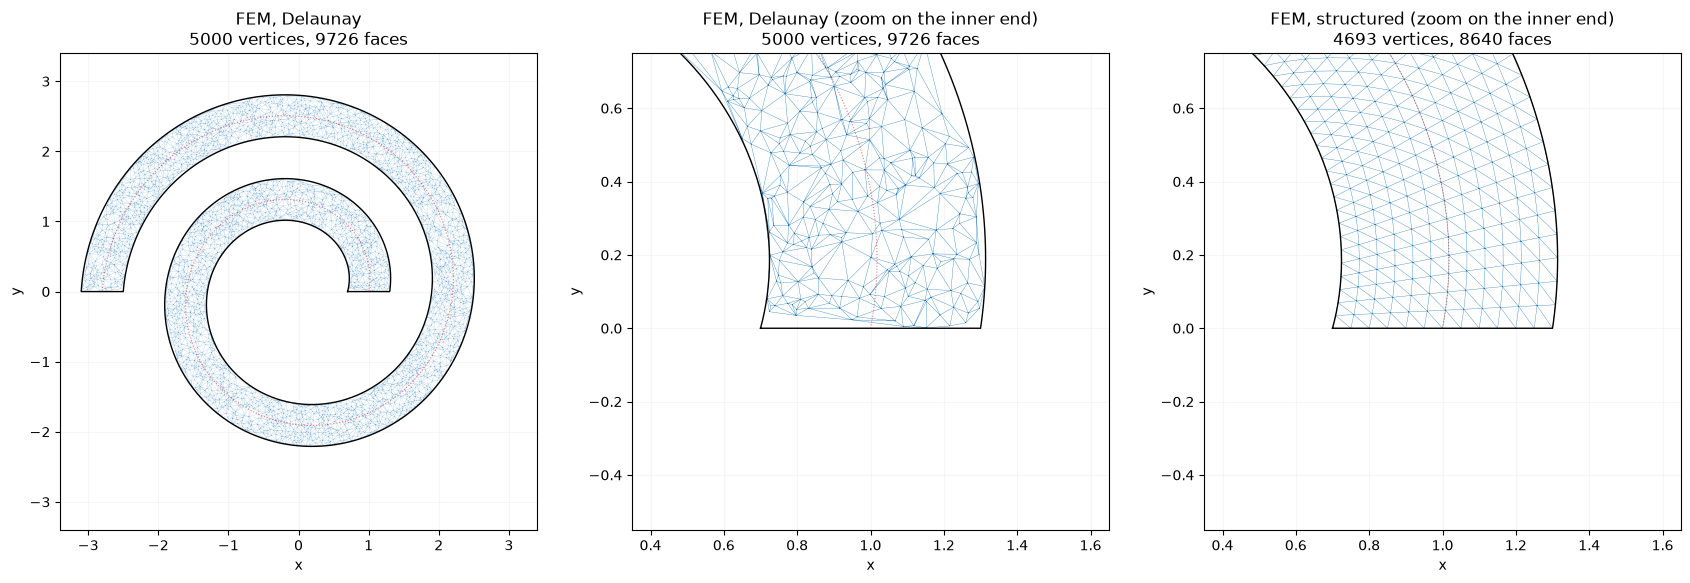

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), constrained_layout=True)
zoom = dict(xlim=(0.35, 1.65), ylim=(-0.55, 0.75))
panels = [("FEM, Delaunay", None), ("FEM, Delaunay", zoom), ("FEM, structured", zoom)]
for ax, (name, window) in zip(axes, panels, strict=True):
    fit = fem_fits[name]
    ax.triplot(fit.vertices[:, 0], fit.vertices[:, 1], fit.faces, linewidth=0.25 if window else 0.08, color="tab:blue")
    roll.finish_axes(ax, grid_alpha=0.1)
    if window:
        ax.set(**window)
    ax.set_title(f"{name}{' (zoom on the inner end)' if window else ''}\n{len(fit.vertices)} vertices, {len(fit.faces)} faces")
plt.show()

**Reading.** All four meshes are discs, and every solve converged. Halving h changes the reference spectrum by at most 2.4·10⁻⁴, so its error is about 10⁻⁴, far below every difference discussed below. Two properties of the Delaunay mesh matter later:

* It covers 10.33 of the 10.74 area units (96%), because random samples never lie exactly on the boundary. Its strip is effectively narrower.
* It has poorly shaped triangles: the smallest angle is 0.04°, and 53% of the triangles are obtuse (these take the obtuse branch of the Voronoi mass rule).

The structured meshes have no obtuse triangles.

## 3 · Spectrum

Graph eigenvalues are in graph units, so each premetric is first compared to the reference up to one global factor $c$ (least squares, $\lambda_i\approx c\,\lambda^{\mathrm{ref}}_i$). Only the relative weights $1/\lambda_i$ across modes affect the RFM field, because $u_t$ does not change when $d$ is multiplied by a constant. The table reports $c$ and the remaining shape error $|\lambda_i/(c\lambda^{\mathrm{ref}}_i)-1|$.

,lambda_1,lambda_32,global_factor_c,median_shape_error,max_shape_error,lambda_32/lambda_1
reference,0.030725,27.887750,1.000000,0.000000,0.000000,907.654904
"FEM, Delaunay",0.030972,29.417443,1.014343,0.010464,0.039936,949.794277
"FEM, structured",0.030735,27.734007,0.995644,0.002905,0.004693,902.365317
fixed Gaussian,0.002460,2.163591,0.078568,0.038684,0.106362,879.533838
variable Gaussian,0.017850,14.390150,0.528448,0.078214,0.135477,806.163703
compact polynomial,0.001715,1.383612,0.051704,0.068155,0.120084,806.904295
smooth bump,0.005398,4.384862,0.162358,0.067039,0.119868,812.268603
binary CkNN,0.024589,19.757473,0.725640,0.080826,0.139042,803.498975


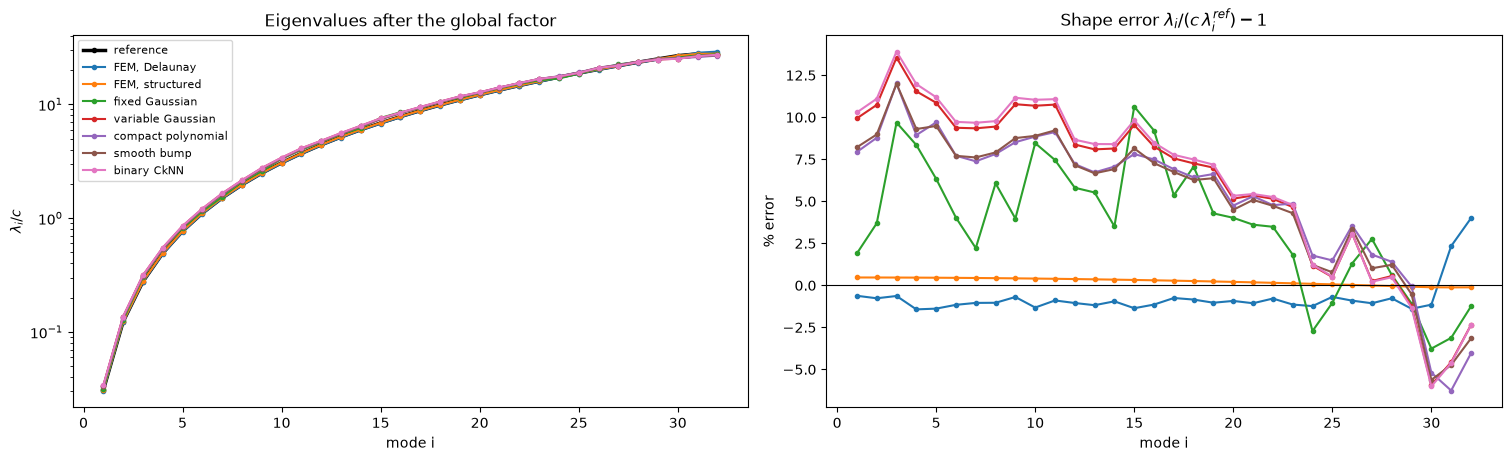

In [5]:
spectra = {"reference": fem_fits["reference"].eigenvalues,
           "FEM, Delaunay": fem_fits["FEM, Delaunay"].eigenvalues,
           "FEM, structured": fem_fits["FEM, structured"].eigenvalues,
           **{name: np.asarray(model.lam, dtype=np.float64) for name, model in kernel_models.items()}}
assert all(len(lam) == n_modes for lam in spectra.values())
lam_ref = spectra["reference"]
spectrum_rows, shape_errors = {}, {}
for name, lam in spectra.items():
    factor = float(lam @ lam_ref / (lam_ref @ lam_ref))
    shape = lam / (factor * lam_ref) - 1
    shape_errors[name] = shape
    spectrum_rows[name] = {"lambda_1": lam[0], "lambda_32": lam[-1], "global_factor_c": factor,
                           "median_shape_error": np.median(np.abs(shape)), "max_shape_error": np.max(np.abs(shape)),
                           "lambda_32/lambda_1": lam[-1] / lam[0]}
spectrum_df = pd.DataFrame(spectrum_rows).T
display(spectrum_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
modes = np.arange(1, n_modes + 1)
for name, lam in spectra.items():
    style = {"color": "black", "linewidth": 2.5} if name == "reference" else {}
    axes[0].plot(modes, lam / spectrum_rows[name]["global_factor_c"], marker=".", label=name, **style)
    if name != "reference":
        axes[1].plot(modes, 100 * shape_errors[name], marker=".", label=name)
axes[0].set(xlabel="mode i", ylabel=r"$\lambda_i / c$", title="Eigenvalues after the global factor", yscale="log")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="mode i", ylabel="% error", title=r"Shape error $\lambda_i/(c\,\lambda_i^{ref})-1$")
axes[0].legend(fontsize=8)
plt.show()

**Reading.** After one global factor:

* FEM on the same 5,000 points reproduces the reference spectrum to 1.0% (median) and 4.0% (max); FEM on the structured mesh to 0.3% and 0.5%.
* The kernel graphs are 3.9–8.1% (median) and 11–14% (max) off; the fixed Gaussian is the most accurate of them.
* The graph spectra are compressed: λ₃₂/λ₁ is 880 for the fixed Gaussian and 800–810 for the other profiles, against 908. Their higher modes therefore carry relatively too much biharmonic weight.

The global factor c (0.05–0.73 for the graphs) only rescales d and leaves the RFM field unchanged. The Delaunay mesh's λ₃₂ is too high (29.4 vs 27.9) because its narrower strip pushes the first across-strip mode up (next section).

## 4 · Eigenfunctions

All eigenvectors are compared at the 5,000 construction points (uniform samples, so the plain dot product approximates the area $L^2$ inner product). **Mode match** is $|\cos|$ between mode $i$ of a premetric and mode $i$ of the reference. Near-degenerate modes may swap or mix, so **captured** also reports the fraction of reference mode $i$ that lies in the span of all 32 modes of the premetric (1 = fully represented).

,median_mode_match,min_mode_match,first_mode_below_0.9,median_captured,min_captured
"FEM, Delaunay",0.998356,0.017340,31.0,0.999752,0.094940
"FEM, structured",0.999999,0.999994,NaN,0.999999,0.999990
fixed Gaussian,0.911692,0.078061,11.0,0.991394,0.065478
variable Gaussian,0.957108,0.015619,23.0,0.996002,0.054660
compact polynomial,0.951902,0.007211,23.0,0.995370,0.096609
smooth bump,0.954211,0.022329,23.0,0.995969,0.086962
binary CkNN,0.957611,0.016199,23.0,0.995765,0.051924


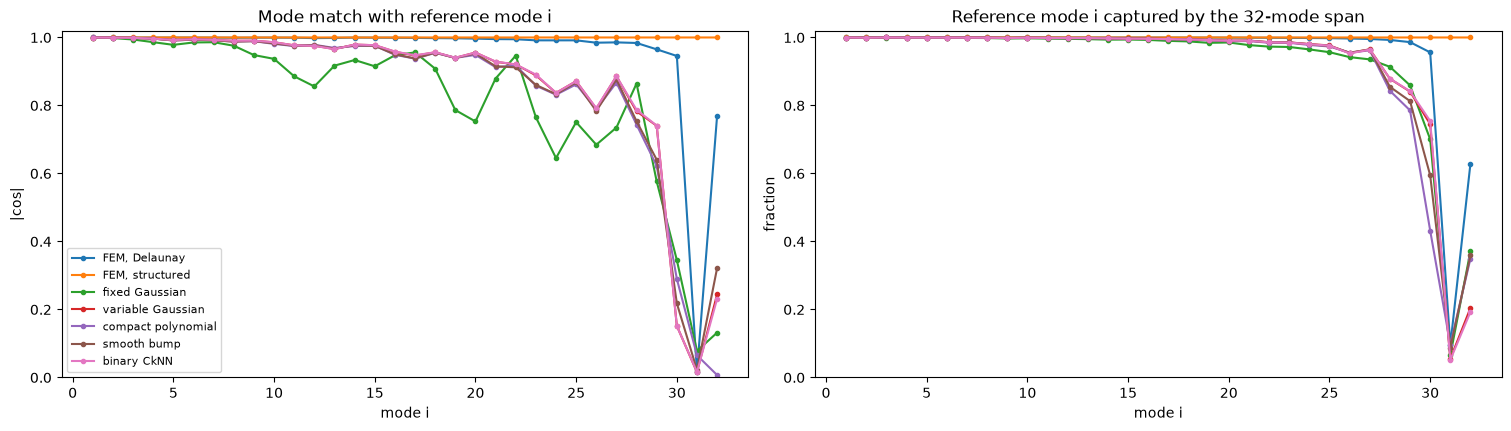

In [6]:
def fem_values(fit, query):
    # Eigenfunction values (not the 1/lambda-weighted coordinates) by barycentric interpolation.
    faces, weights = jax.jit(jax.vmap(fit.model.face_and_barycentric))(jnp.asarray(query))
    corner_ids = np.asarray(fit.faces)[np.asarray(faces)]
    return np.einsum("nk,nkm->nm", np.asarray(weights, dtype=np.float64), fit.eigenvectors[corner_ids])

node_values = {"reference": fem_values(fem_fits["reference"], construction_points),
               "FEM, Delaunay": fem_fits["FEM, Delaunay"].eigenvectors,
               "FEM, structured": fem_values(fem_fits["FEM, structured"], construction_points),
               **{name: np.asarray(model.Phi, dtype=np.float64) for name, model in kernel_models.items()}}
unit = {name: values / np.linalg.norm(values, axis=0) for name, values in node_values.items()}
mode_rows, mode_match, captured = {}, {}, {}
for name, values in unit.items():
    if name == "reference":
        continue
    mode_match[name] = np.abs(np.sum(values * unit["reference"], axis=0))
    basis, _ = np.linalg.qr(values)
    captured[name] = np.sum((basis.T @ unit["reference"]) ** 2, axis=0)
    mode_rows[name] = {"median_mode_match": np.median(mode_match[name]), "min_mode_match": mode_match[name].min(),
                       "first_mode_below_0.9": int(np.argmax(mode_match[name] < 0.9)) + 1 if np.any(mode_match[name] < 0.9) else None,
                       "median_captured": np.median(captured[name]), "min_captured": captured[name].min()}
display(pd.DataFrame(mode_rows).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), constrained_layout=True)
for name in mode_match:
    axes[0].plot(modes, mode_match[name], marker=".", label=name)
    axes[1].plot(modes, captured[name], marker=".", label=name)
axes[0].set(xlabel="mode i", ylabel="|cos|", title="Mode match with reference mode i", ylim=(0, 1.02))
axes[1].set(xlabel="mode i", ylabel="fraction", title="Reference mode i captured by the 32-mode span", ylim=(0, 1.02))
axes[0].legend(fontsize=8)
plt.show()

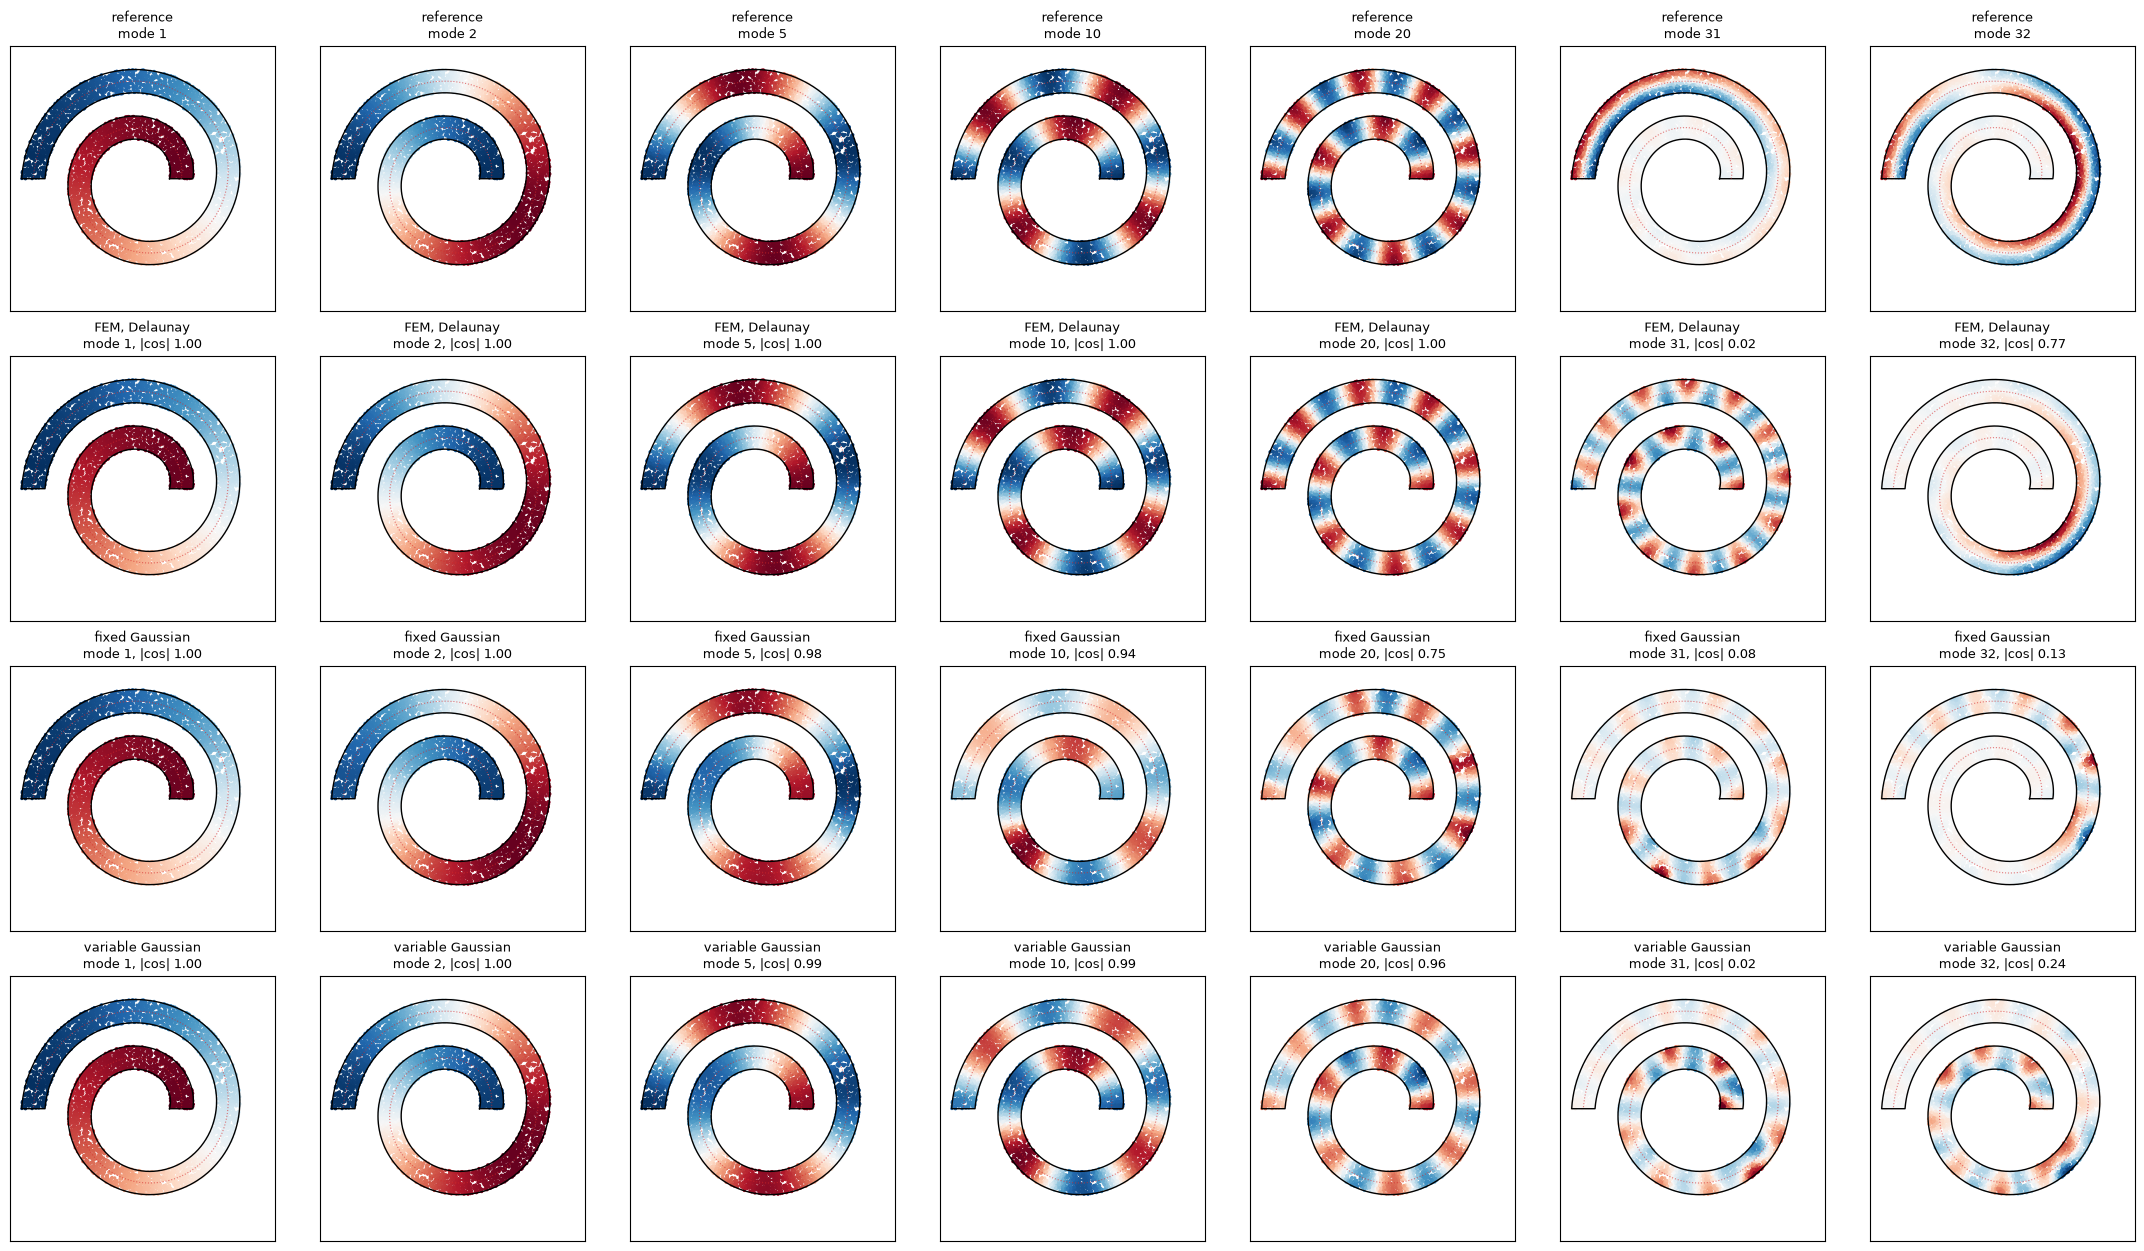

In [7]:
shown_modes = [1, 2, 5, 10, 20, 31, 32]
shown_rows = ["reference", "FEM, Delaunay", "fixed Gaussian", "variable Gaussian"]
fig, axes = plt.subplots(len(shown_rows), len(shown_modes), figsize=(3.1 * len(shown_modes), 3.1 * len(shown_rows)),
                         constrained_layout=True)
for row, name in enumerate(shown_rows):
    for column, mode in enumerate(shown_modes):
        ax = axes[row, column]
        values = unit[name][:, mode - 1]
        values = values * np.sign(values @ unit["reference"][:, mode - 1])  # align the sign with the reference
        scale = np.abs(values).max()
        ax.scatter(*construction_points.T, c=values, s=2, cmap="RdBu_r", vmin=-scale, vmax=scale)
        roll.finish_axes(ax, grid_alpha=0.0)
        ax.set(xticks=[], yticks=[], xlabel="", ylabel="")
        ax.set_title(f"{name}\nmode {mode}" + ("" if name == "reference" else f", |cos| {mode_match[name][mode - 1]:.2f}"),
                     fontsize=9)
plt.show()

**Reading.**

* **FEM, structured** matches every reference mode (|cos| ≥ 0.99999).
* **FEM, Delaunay** matches modes 1–30 (|cos| ≥ 0.95, median 0.998). Its modes 31–32 differ: reference mode 31 is the *first mode that varies across the strip* (λ = 27.7 ≈ (π/0.6)²), and on the narrower Delaunay strip that mode lies above the 32-mode cut-off. Only 9% of it is captured. Every kernel graph misses it too (6–10% captured).
* **Kernel modes drift below that.** The variable-bandwidth profiles stay above |cos| = 0.9 up to mode 22. The fixed Gaussian drops below 0.9 at mode 11 and reaches 0.58 at mode 29. The 32-mode span is still right (≥ 0.94 captured up to mode 27), so the graph modes are mixtures of neighbouring reference modes.
* The figure shows one symptom: the fixed Gaussian's higher modes split their amplitude unevenly between the inner and outer halves of the roll. The RMS ratio is 0.86–1.64 for modes 10–25, against 0.97–1.00 for the reference.

## 5 · Distances and OT couplings

Biharmonic distances on 2,000 random pairs of roll points and on all 250 × 250 source–target pairs (the OT cost of the notebook), compared with the reference after one best global scale factor. The entropic OT couplings ($\varepsilon=0.05$, unsquared biharmonic cost, as in training) are compared by total-variation distance to the reference coupling. The Euclidean-cost coupling is shown as a yardstick.

In [8]:
premetrics = {"reference": fem_fits["reference"].model, "FEM, Delaunay": fem_fits["FEM, Delaunay"].model,
              "FEM, structured": fem_fits["FEM, structured"].model, **kernel_models}
embeds = {name: jax.jit(jax.vmap(model.extend_point)) for name, model in premetrics.items()}
distance_fns = {name: jax.jit(model.distance_grad_and_norm_batch) for name, model in premetrics.items()}

pair_points = roll.sample_uniform(4_000, np.random.default_rng(7)).astype(np.float32)
pair_x, pair_y = jnp.asarray(pair_points[:2000]), jnp.asarray(pair_points[2000:])
random_distances = {name: np.asarray(fn(pair_x, pair_y)[0], dtype=np.float64) for name, fn in distance_fns.items()}
costs = {name: cdist(np.asarray(embed(jnp.asarray(source)), dtype=np.float64), np.asarray(embed(jnp.asarray(target)), dtype=np.float64))
         for name, embed in embeds.items()}

def scale_fit_error(values, reference):
    factor = values @ reference / (values @ values)
    return np.sqrt(np.mean((factor * values - reference) ** 2)) / np.sqrt(np.mean(reference**2))

couplings = {name: np.asarray(jax.jit(flows.make_entropic_match_fn(0.05, embed=embed))(source, target), dtype=np.float64)
             for name, embed in embeds.items()}
couplings["Euclidean cost (yardstick)"] = np.asarray(jax.jit(flows.make_entropic_match_fn(0.05))(source, target), dtype=np.float64)
reference_plan = couplings["reference"] / couplings["reference"].sum()

distance_rows = {}
for name in couplings:
    plan = couplings[name] / couplings[name].sum()
    row = {"coupling_TV_to_reference": 0.5 * np.abs(plan - reference_plan).sum(),
           "same_argmax_partner": np.mean(plan.argmax(axis=1) == reference_plan.argmax(axis=1))}
    if name in premetrics:
        row = {"random_pairs_rel_rmse": scale_fit_error(random_distances[name], random_distances["reference"]),
               "random_pairs_spearman": spearmanr(random_distances[name], random_distances["reference"])[0],
               "ot_cost_rel_rmse": scale_fit_error(costs[name].ravel(), costs["reference"].ravel()),
               "ot_cost_spearman": spearmanr(costs[name].ravel(), costs["reference"].ravel())[0], **row}
    distance_rows[name] = row
display(pd.DataFrame(distance_rows).T)

,random_pairs_rel_rmse,random_pairs_spearman,ot_cost_rel_rmse,ot_cost_spearman,coupling_TV_to_reference,same_argmax_partner
reference,0.000000,1.000000,0.000000,1.000000,0.000000e+00,1.000
"FEM, Delaunay",0.002748,0.999982,0.000245,0.999550,3.008301e-06,0.960
"FEM, structured",0.000046,1.000000,0.000004,1.000000,6.158924e-07,0.968
fixed Gaussian,0.021169,0.999122,0.001341,0.985797,2.372272e-05,0.932
variable Gaussian,0.007843,0.999882,0.000736,0.997404,1.712689e-05,0.940
compact polynomial,0.007660,0.999882,0.000864,0.996046,1.898571e-05,0.952
smooth bump,0.007769,0.999882,0.000829,0.996643,1.821074e-05,0.956
binary CkNN,0.007865,0.999881,0.000741,0.997333,1.742472e-05,0.948
Euclidean cost (yardstick),NaN,NaN,NaN,NaN,4.304101e-02,0.132


**Reading.**

* **Random pairs.** Distance errors follow the spectrum: 0.3% (FEM, Delaunay) and 0.005% (FEM, structured), against 0.8% (variable-bandwidth profiles) and 2.1% (fixed Gaussian). All rank correlations are ≥ 0.999.
* **OT cost between the two clouds.** All premetrics agree to within 0.13%.
* **Couplings.** The entropic couplings are practically identical: total-variation distance to the reference is ≤ 2.4·10⁻⁵, against 0.043 for the Euclidean cost.

**So the discretization does not change which pairs RFM trains on.**

## 6 · Conditional RFM fields

The raw field $u_{0.5}(x\mid x_1)$ towards the inner Gaussian mean (the notebook's `kernel_target`) is evaluated at 4,000 fresh uniform roll points, without projection or guard. Its direction is compared with the reference by the angle between the two fields. Its magnitude is compared by the speed ratio $|u|/|u^{\mathrm{ref}}|$, which needs no scale fit: $d/\|\nabla d\|$ does not change when $d$ is rescaled. Points are split into the bulk, a 0.05 boundary layer, and a 0.5 neighbourhood of the target. **outward_boundary_fraction** is the notebook's raw boundary diagnostic: the fraction of boundary probes where the raw field points out of the roll.

In [9]:
field_time = 0.5
field_points = roll.sample_uniform(4_000, np.random.default_rng(11)).astype(np.float32)
offset = np.abs(roll.radial_coordinate(field_points))
arc = roll.arc_length(roll.roll_angle(field_points))
near_boundary = (offset > roll.half_width - 0.05) | (arc < 0.05) | (arc > roll.centerline_length - 0.05)
near_target = np.linalg.norm(field_points - field_target, axis=1) < 0.5
regions = {"bulk": ~near_boundary & ~near_target, "boundary layer": near_boundary, "near target": near_target}

def raw_field(model, query):
    interpolator = RFMInterpolation(model, project_to_manifold=False)
    query = jnp.asarray(query)
    targets = jnp.broadcast_to(jnp.asarray(field_target), query.shape)
    return np.asarray(jax.jit(interpolator.u_t)(query, targets, field_time), dtype=np.float64)

fields = {name: raw_field(model, field_points) for name, model in premetrics.items()}
probe_fields = {name: raw_field(model, roll.probe_points) for name, model in premetrics.items()}

def angle_deg(a, b):
    cos = np.sum(a * b, axis=1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))
    return np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))

field_names = [name for name in premetrics if name not in ("reference", "binary CkNN")]  # binary CkNN: zero field
field_angles, field_rows = {}, {}
for name in field_names:
    velocities = fields[name]
    angles = angle_deg(velocities, fields["reference"])
    ratio = np.linalg.norm(velocities, axis=1) / np.linalg.norm(fields["reference"], axis=1)
    field_angles[name] = angles
    row = {"angle_median": np.median(angles), "angle_p90": np.quantile(angles, 0.9),
           "fraction_angle>30": np.mean(angles > 30),
           "speed_ratio_median": np.median(ratio), "speed_ratio_p10": np.quantile(ratio, 0.1),
           "speed_ratio_p90": np.quantile(ratio, 0.9)}
    for region, mask in regions.items():
        row[f"angle_median[{region}]"] = np.median(angles[mask])
        row[f"angle_p90[{region}]"] = np.quantile(angles[mask], 0.9)
    field_rows[name] = row
field_df = pd.DataFrame(field_rows).T
field_df["outward_boundary_fraction"] = [roll.probe_diagnostic(probe_fields[name])["outward_boundary_fraction"]
                                         for name in field_df.index]
print({region: int(mask.sum()) for region, mask in regions.items()},
      "| reference outward_boundary_fraction:", roll.probe_diagnostic(probe_fields["reference"])["outward_boundary_fraction"])
display(field_df)

{'bulk': 3123, 'boundary layer': 688, 'near target': 222} | reference outward_boundary_fraction: 0.7970297029702971


,angle_median,angle_p90,fraction_angle>30,speed_ratio_median,speed_ratio_p10,speed_ratio_p90,angle_median[bulk],angle_p90[bulk],angle_median[boundary layer],angle_p90[boundary layer],angle_median[near target],angle_p90[near target],outward_boundary_fraction
"FEM, Delaunay",0.844123,2.825807,0.00150,0.994464,0.960239,1.027610,0.747454,2.217168,1.615419,5.415418,1.215533,3.501220,0.559406
"FEM, structured",0.358259,0.926280,0.00025,0.999603,0.985497,1.014514,0.355600,0.907465,0.373798,1.029637,0.349810,1.222722,0.782178
fixed Gaussian,4.756301,12.753414,0.00300,1.143383,0.732487,1.692737,4.801087,12.677568,3.830701,10.247866,8.684101,15.971988,0.391089
variable Gaussian,3.445294,9.172455,0.01050,4.243824,3.516563,5.117536,3.478472,9.275243,2.915220,7.912995,4.776682,10.500109,0.495050
compact polynomial,4.242342,11.124334,0.00625,1.020382,0.768130,1.308353,4.396654,11.365704,3.307384,8.124784,4.771191,13.046142,0.465347
smooth bump,4.036449,10.691512,0.00850,1.009604,0.786345,1.282998,4.196980,10.906973,3.149600,8.284352,5.054382,11.902225,0.485149


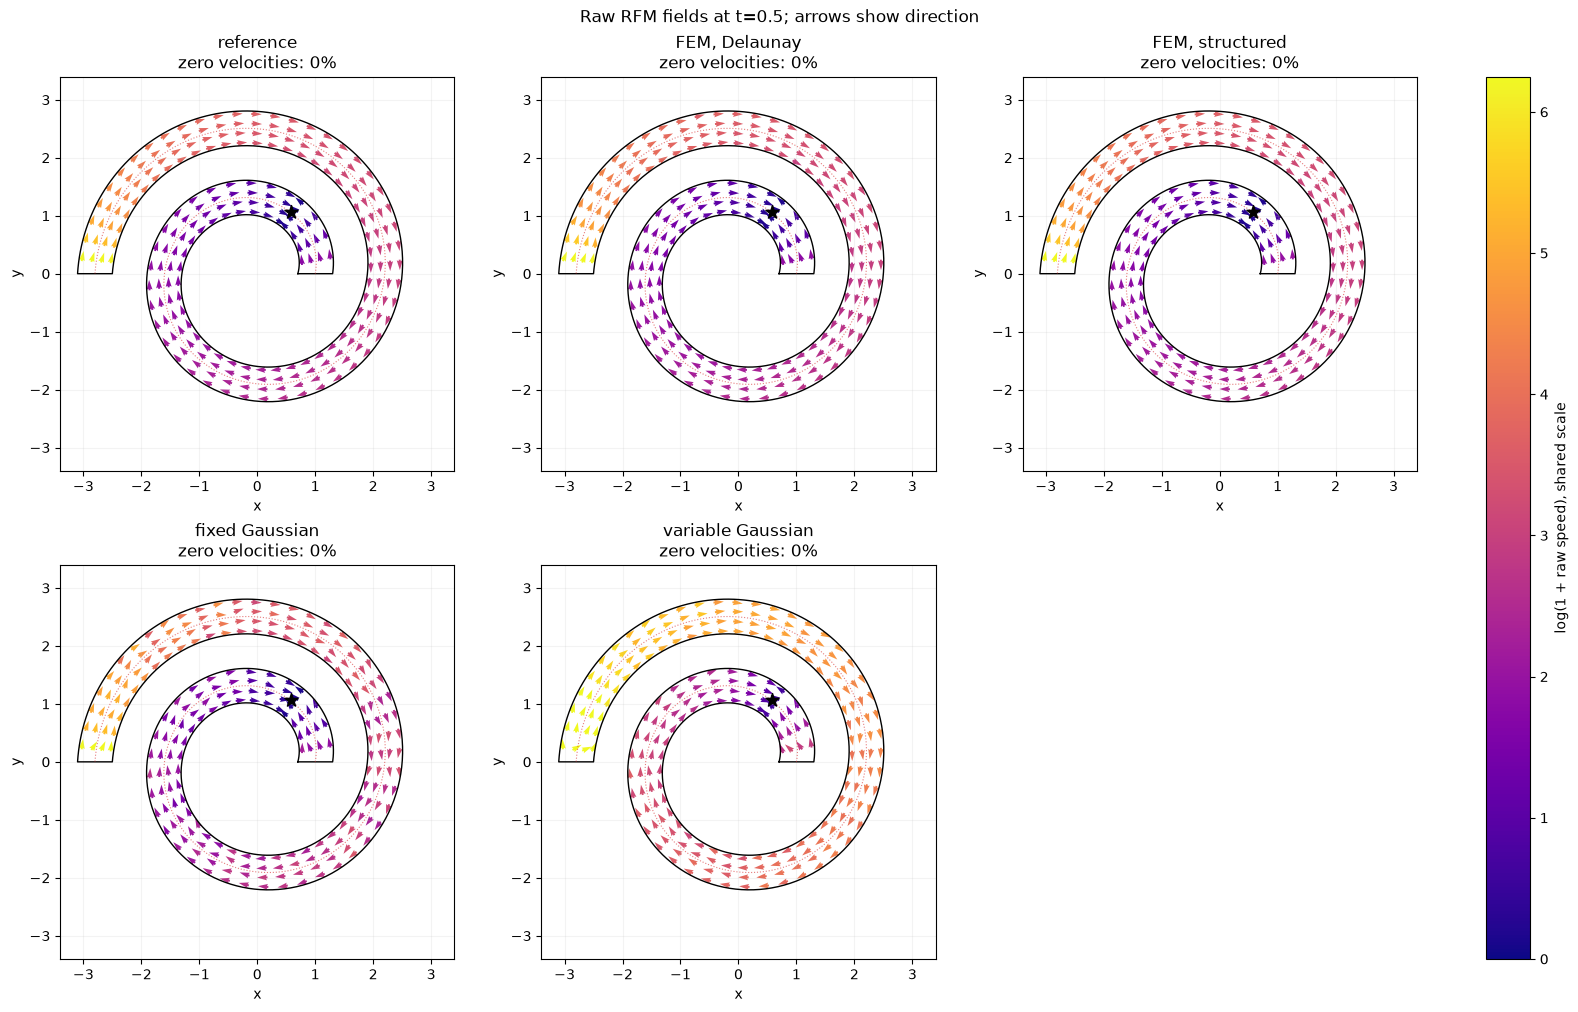

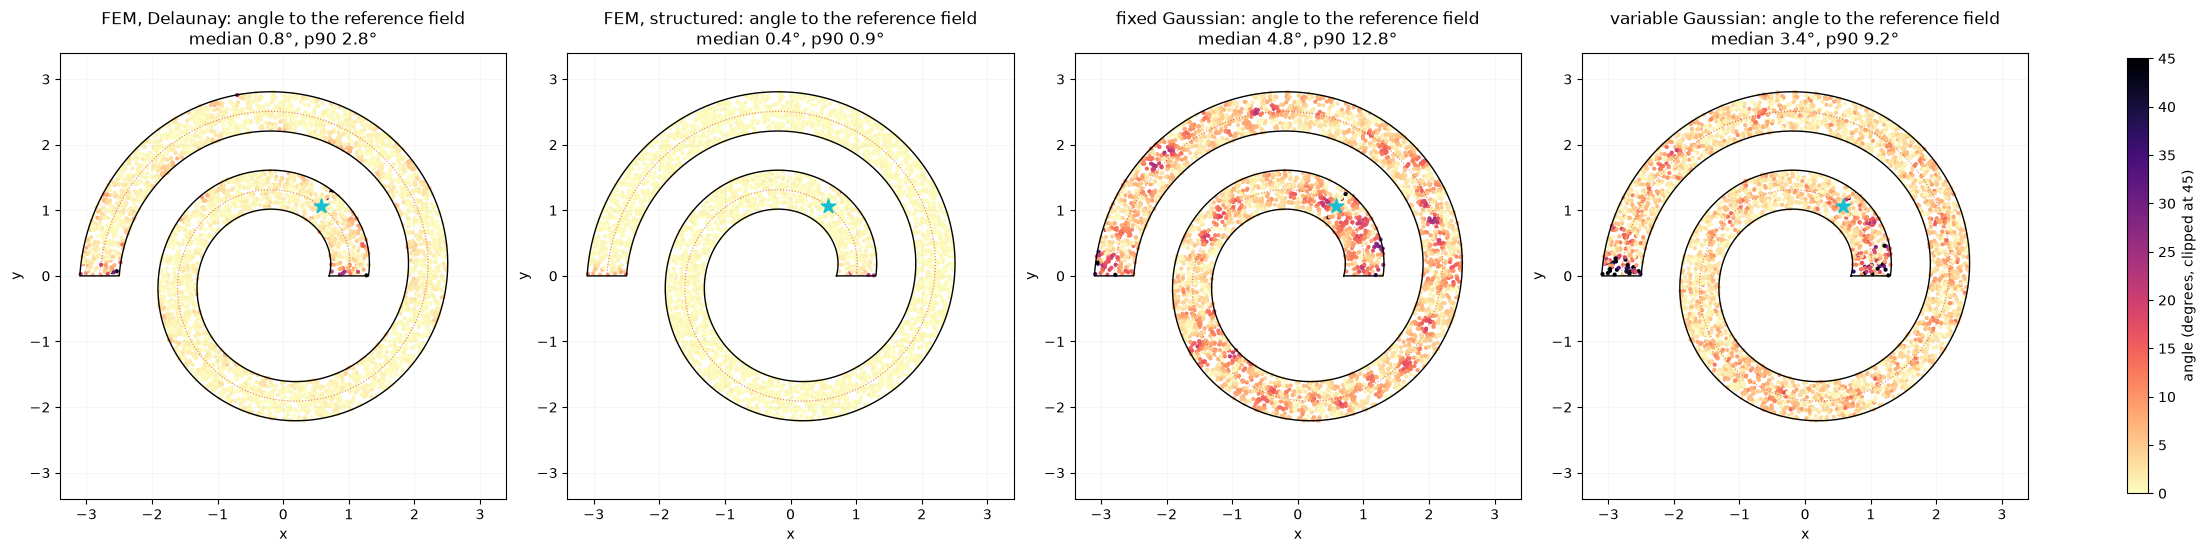

In [10]:
grid_points = roll.field_grid(n_along=60, n_across=4)
shown = ["reference", "FEM, Delaunay", "FEM, structured", "fixed Gaussian", "variable Gaussian"]
plotting.plot_kernel_fields(roll, grid_points, {name: raw_field(premetrics[name], grid_points) for name in shown},
                            field_target, field_time)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.6), constrained_layout=True)
for ax, name in zip(axes, ["FEM, Delaunay", "FEM, structured", "fixed Gaussian", "variable Gaussian"], strict=True):
    image = ax.scatter(*field_points.T, c=field_angles[name], s=4, cmap="magma_r", vmin=0, vmax=45)
    roll.finish_axes(ax, grid_alpha=0.1)
    ax.scatter(*field_target, s=120, marker="*", color="tab:cyan", zorder=5)
    ax.set_title(f"{name}: angle to the reference field\nmedian {np.median(field_angles[name]):.1f}°, "
                 f"p90 {np.quantile(field_angles[name], 0.9):.1f}°")
fig.colorbar(image, ax=axes, label="angle (degrees, clipped at 45)", shrink=0.8)
plt.show()

**Reading.** This is where the discretizations separate.

* **FEM.** The piecewise-constant gradient points within 0.8° of the reference direction (median; 90th percentile 2.8°) on the Delaunay mesh, and within 0.4° (0.9°) on the structured mesh. The speed is within ±3% (10th–90th percentile 0.96–1.03).
* **Nyström, direction.** Off by 3.4–4.8° (median) and 9–13° (90th percentile), and worst near the target (fixed Gaussian: 8.7° median, 16° at the 90th percentile).
* **Nyström, speed.** Much more scatter: 0.73–1.69 for the fixed Gaussian (median 1.14) and 0.77–1.31 for the compact polynomial. The variable Gaussian is **4.2 times too fast** (3.5–5.1).

In the angle maps, the Nyström errors are fine-grained noise all over the roll. The Delaunay FEM errors sit mostly in the boundary layer.

### Where the speed error comes from: jumps in the extension

The speed ratio needs $d/\|\nabla d\|$, so a wrong $\|\nabla d\|$ shows up directly. Truncated Gaussian profiles have a jump at the edge of the CkNN support: the weight is still $e^{-1/2}\approx0.61$ there for the variable Gaussian and $\approx0.02$ for the fixed Gaussian. Every time a construction point enters or leaves a query's support, the Nyström extension jumps. The analytic gradient differentiates only the smooth part between jumps. The check compares the secant slope $\big(d(x+he)-d(x-he)\big)/2h$ with the analytic directional derivative, along the reference gradient direction $e$, at 400 points away from the edges. A ratio of 1 means the analytic gradient sees all of the variation.

In [11]:
check_points = field_points[np.abs(roll.radial_coordinate(field_points)) < 0.2][:400]
check_targets = jnp.broadcast_to(jnp.asarray(field_target), check_points.shape)
_, reference_gradient, _ = distance_fns["reference"](jnp.asarray(check_points), check_targets)
direction = np.asarray(reference_gradient) / np.linalg.norm(np.asarray(reference_gradient), axis=1, keepdims=True)
secant_rows = {}
for name in ["reference", *field_names]:
    distance_fn = distance_fns[name]
    analytic = np.sum(np.asarray(distance_fn(jnp.asarray(check_points), check_targets)[1]) * direction, axis=1)
    row = {}
    for h in (0.001, 0.01, 0.05, 0.15):
        plus = np.asarray(distance_fn(jnp.asarray(check_points + h * direction, dtype=jnp.float32), check_targets)[0])
        minus = np.asarray(distance_fn(jnp.asarray(check_points - h * direction, dtype=jnp.float32), check_targets)[0])
        row[f"secant/analytic, h={h}"] = np.median((plus - minus) / (2 * h) / analytic)
    secant_rows[name] = row
display(pd.DataFrame(secant_rows).T)

,"secant/analytic, h=0.001","secant/analytic, h=0.01","secant/analytic, h=0.05","secant/analytic, h=0.15"
reference,0.999970,1.000004,0.999788,0.998028
"FEM, Delaunay",1.000017,0.999995,0.999929,0.997227
"FEM, structured",1.000012,0.999990,0.999366,0.997328
fixed Gaussian,1.063623,1.091871,1.097032,1.112048
variable Gaussian,3.961588,4.336285,4.217002,4.222300
compact polynomial,1.000042,1.001231,1.001656,0.998099
smooth bump,0.999891,1.000174,0.998767,0.982499


**Reading.**

* **Continuous kernels and FEM.** For the FEM premetrics and the two profiles that vanish continuously at the edge of the support (compact polynomial, smooth bump), secant and analytic slopes agree to within 2%. The analytic gradient sees all of the variation.
* **Variable Gaussian.** The secant slope is **4.0–4.3 times** the analytic one at every step size, down to h = 0.001. Its extension is a dense staircase: about three quarters of the variation sits in jumps that the analytic gradient ignores. This is the factor-4 speed error.
* **Fixed Gaussian.** The same effect at 6–11%, since its weight at the cut-off is only about 0.02.

The `SymmetricBandwidthKernel` docstring mentions these jumps. Their effect on the field is systematic, not local.

### The raw field at the boundary

App. G.2 of the RFM paper relies on Neumann eigenfunctions, so that $\nabla d$ is tangent to the boundary. The notebook's `outward_boundary_fraction` counts probes with *any* outward component ($u\cdot n<-10^{-6}$). For a field that is tangent up to round-off, this is a coin flip, so the reference scores high on it. The table below measures the normal component relative to the speed instead.

In [12]:
probe_normals = np.asarray(roll.probe_normals, dtype=np.float64)
boundary_rows = {}
for name in ["reference", *field_names]:
    velocities = probe_fields[name]
    cos_normal = np.sum(velocities * probe_normals, axis=1) / np.linalg.norm(velocities, axis=1)  # > 0 inward
    boundary_rows[name] = {"median |u.n|/|u|": np.median(np.abs(cos_normal)), "p90 |u.n|/|u|": np.quantile(np.abs(cos_normal), 0.9),
                           "outward by > 5 deg": np.mean(cos_normal < -np.sin(np.radians(5))),
                           "outward by > 20 deg": np.mean(cos_normal < -np.sin(np.radians(20))),
                           "any outward component (notebook)": np.mean(np.sum(velocities * probe_normals, axis=1) < -1e-6)}
display(pd.DataFrame(boundary_rows).T)

,median |u.n|/|u|,p90 |u.n|/|u|,outward by > 5 deg,outward by > 20 deg,any outward component (notebook)
reference,0.001497,0.004117,0.000000,0.00000,0.797030
"FEM, Delaunay",0.040978,0.142970,0.084158,0.00000,0.559406
"FEM, structured",0.011869,0.033597,0.000000,0.00000,0.782178
fixed Gaussian,0.069861,0.236584,0.084158,0.00000,0.391089
variable Gaussian,0.052604,0.166041,0.138614,0.00495,0.495050
compact polynomial,0.051896,0.173870,0.133663,0.00495,0.465347
smooth bump,0.056635,0.189872,0.128713,0.00495,0.485149


**Reading.**

* **Reference.** On the converged mesh, the raw field is tangent to the boundary to 0.15% (median |u·n|/|u|), as the Neumann argument of App. G.2 predicts.
* **FEM, coarse meshes.** 1.2% on the structured 5k mesh. 4% on the Delaunay mesh, where 8% of the probes point outward by more than 5° (none by more than 20°).
* **Kernel fields.** 5–7% (median); 8–14% of probes beyond 5°, 0.5% beyond 20°.

The notebook's "any outward component" fraction is 0.80 for the reference. It counts the sign of round-off-sized normal components, so it is not a usable diagnostic.

## 7 · Conditional Euler paths (kernel-section protocol)

The protocol of the swiss roll notebook's kernel section: 12 starts from the outer Gaussian, one target (the inner Gaussian mean), Euler steps $x\leftarrow x+h\,u_t(x)$ to $t=0.99$. **Unprojected** uses the raw field. **Guarded** projects onto the roll and applies the tangent-cone guard (`roll.guarded_interpolator`), with 800 steps and with 1,600 steps.

In [13]:
path_names = ["reference", "FEM, Delaunay", "FEM, structured", "fixed Gaussian", "variable Gaussian",
              "compact polynomial", "smooth bump"]
starts = outer_gaussian_points[np.random.default_rng(2026).choice(len(outer_gaussian_points), 12, replace=False)].astype(np.float32)
final_time, euler_steps = 0.99, 800

euler_paths, euler_rows = {}, []
for name in path_names:
    for mode, guarded, steps in [("unprojected", False, euler_steps), ("roll + cone", True, euler_steps),
                                 ("roll + cone, 1600 steps", True, 2 * euler_steps)]:
        started = time.perf_counter()
        path, _ = kernels.integrate_euler_paths(kernels.make_interpolator(premetrics[name], roll, guarded),
                                                starts, field_target, final_time, steps)
        errors = np.linalg.norm(path[-1] - field_target, axis=1)
        euler_paths[name, mode] = path
        euler_rows.append({"premetric": name, "mode": mode, "mean_final_euclidean": errors.mean(),
                           "fraction_within_0.1": np.mean(errors < 0.1),
                           "mean_path_length": np.linalg.norm(np.diff(path, axis=0), axis=-1).sum(axis=0).mean(),
                           **roll.path_geometry(path), "seconds": time.perf_counter() - started})
euler_df = pd.DataFrame(euler_rows)
display(euler_df.pivot(index="premetric", columns="mode", values="mean_final_euclidean").loc[path_names]
        .rename(columns=lambda c: f"mean endpoint error, {c}"))
display(euler_df.set_index(["premetric", "mode"]).loc[path_names])

mode,"mean endpoint error, roll + cone","mean endpoint error, roll + cone, 1600 steps","mean endpoint error, unprojected"
premetric,,,
reference,0.266558,0.277394,0.273444
"FEM, Delaunay",0.276602,0.280143,0.296924
"FEM, structured",0.277857,0.276451,0.301465
fixed Gaussian,0.172430,0.179171,0.170207
variable Gaussian,0.062791,0.051359,0.087109
compact polynomial,0.259783,0.259285,0.271676
smooth bump,0.260177,0.259422,0.260495


mean_final_euclidean  fraction_within_0.1  mean_path_length  max_step_length  max_segment_gap_penetration  gap_crossing_segment_fraction  max_domain_violation   seconds
premetric          mode                                                                                                                                                                                             
reference          unprojected                          0.273444             0.000000         14.614200         0.195919                 7.223631e-02                       0.077500          7.223631e-02  1.453750
                   roll + cone                          0.266558             0.000000         14.595166         0.195919                 3.073337e-07                       0.000000          3.073337e-07  2.306220
                   roll + cone, 1600 steps              0.277394             0.000000         14.459334         0.097960                 3.122849e-07                       0.000000          3.122849e-07  3.008400
FEM, Delaunay      unprojected                          0.296924             0.000000         14.569268         0.183063                 1.245066e-01                       0.241250          1.245066e-01  0.581557
                   roll + cone                          0.276602             0.000000         14.554142         0.183063                 2.968425e-07                       0.000000          2.968425e-07  1.639394
                   roll + cone, 1600 steps              0.280143             0.000000         14.450134         0.091532                 3.227031e-07                       0.000000          3.227031e-07  1.886581
FEM, structured    unprojected                          0.301465             0.000000         14.655010         0.195599                 2.026693e-01                       0.162812          2.026693e-01  1.074630
                   roll + cone                          0.277857             0.000000         14.619258         0.195599                 3.121440e-06                       0.000000          3.173039e-07  2.098889
                   roll + cone, 1600 steps              0.276451             0.000000         14.535213         0.097799                 4.909344e-06                       0.000000          3.496416e-07  2.659462
fixed Gaussian     unprojected                          0.170207             0.000000         15.042087         0.221262                 5.693209e-03                       0.000208          5.693209e-03  0.883652
                   roll + cone                          0.172430             0.000000         15.025914         0.221262                 0.000000e+00                       0.000000          0.000000e+00  1.710570
                   roll + cone, 1600 steps              0.179171             0.000000         14.861076         0.114186                 2.384221e-07                       0.000000          2.384221e-07  1.942803
variable Gaussian  unprojected                          0.087109             0.750000         16.226637         0.849538                 1.801143e-01                       0.147187          1.790931e-01  0.686645
                   roll + cone                          0.062791             0.750000         15.994466         0.818007                 2.247797e-07                       0.000000          2.247797e-07  1.868027
                   roll + cone, 1600 steps              0.051359             0.833333         15.600430         0.409004                 3.923293e-06                       0.000000          2.794010e-07  2.044759
compact polynomial unprojected                          0.271676             0.000000         14.616738         0.193971                 5.989476e-02                       0.106563          5.989476e-02  0.756590
                   roll + cone                          0.259783             0.000000         14.620438         0.193973                 1.842334e-07                       0.000000          1.842334e-07  1.8790

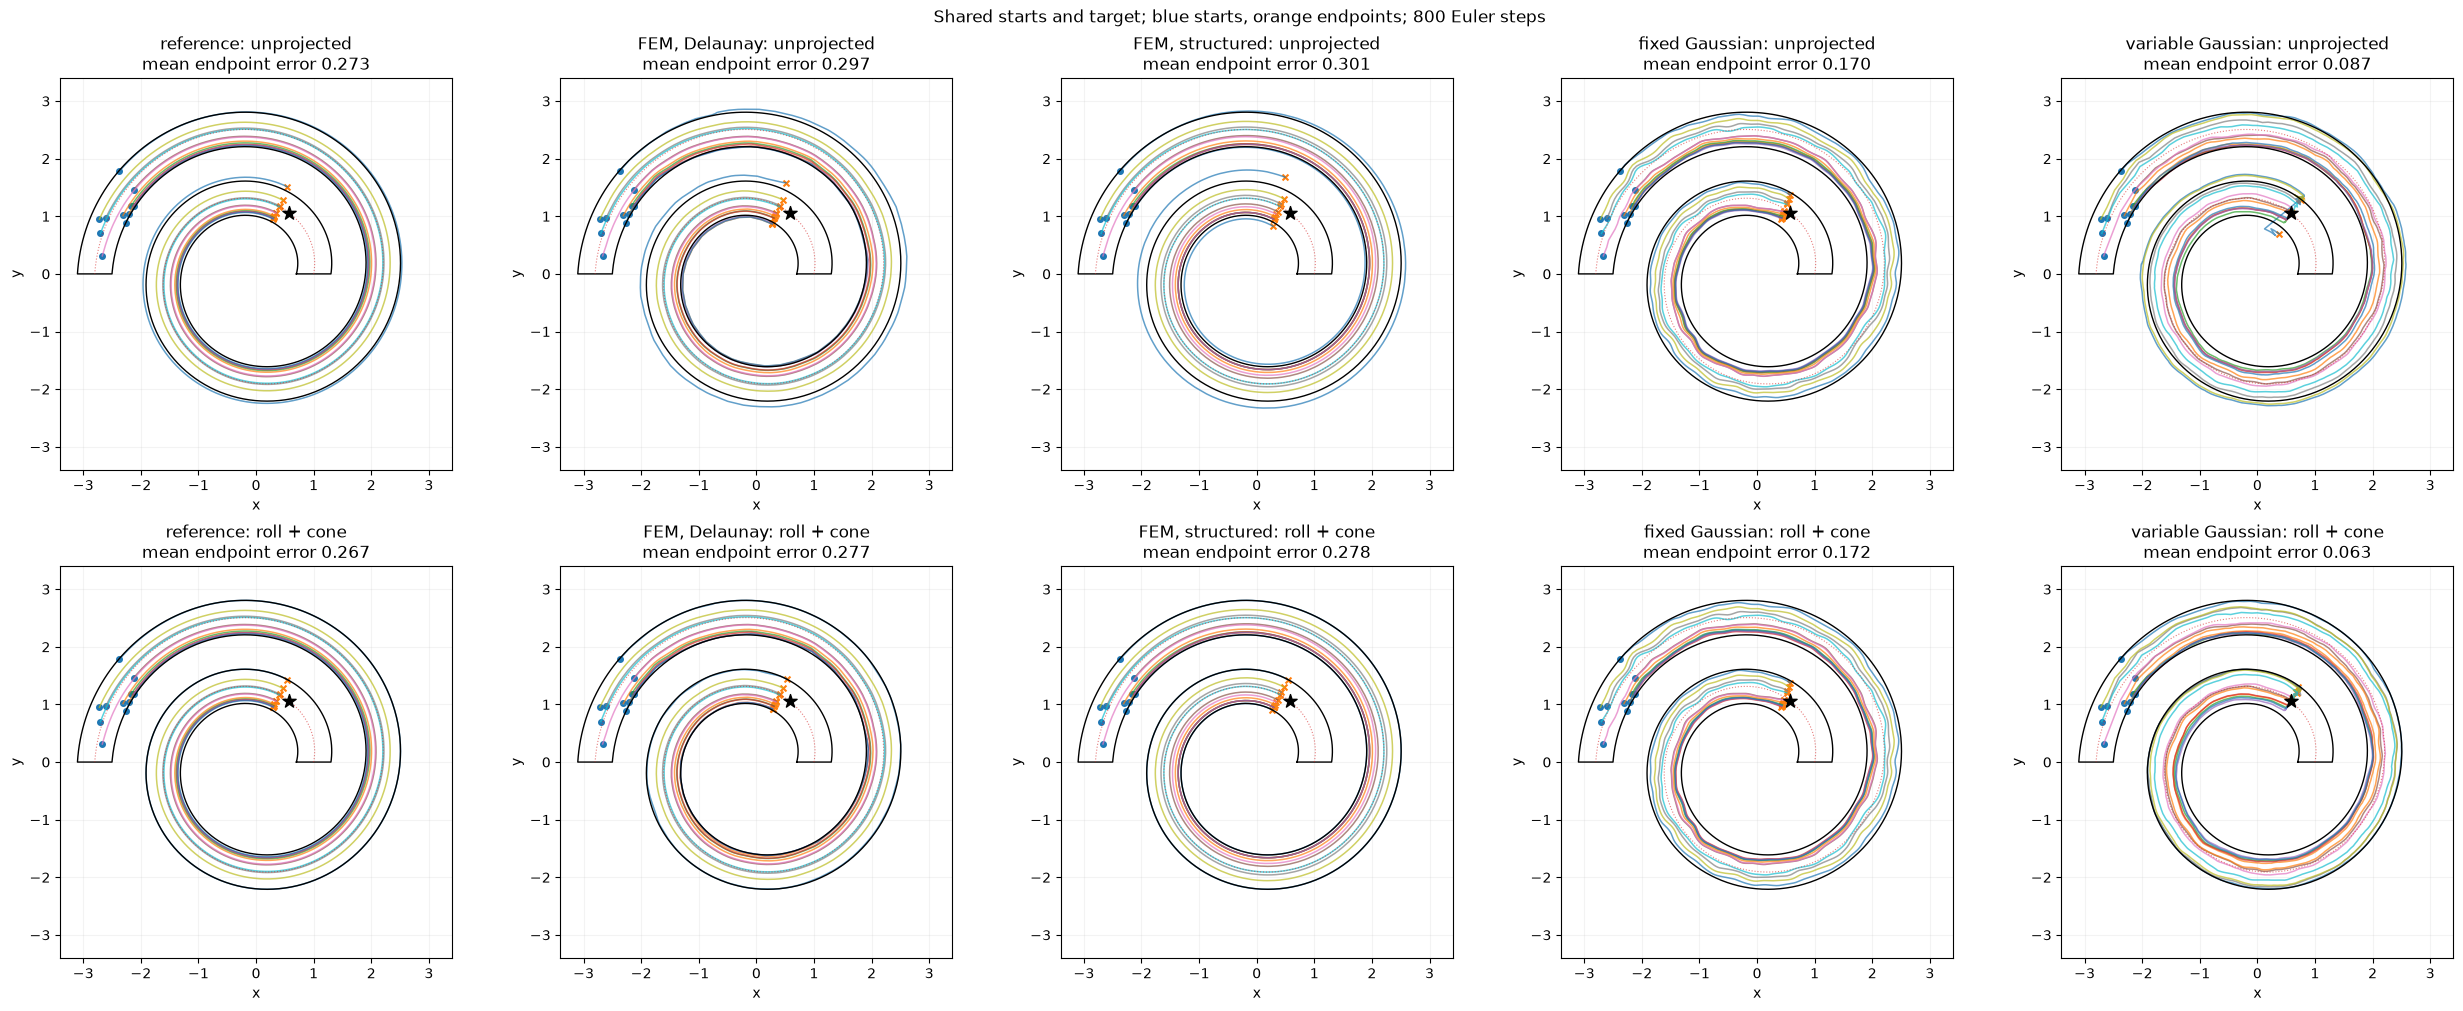

In [14]:
plot_names = ["reference", "FEM, Delaunay", "FEM, structured", "fixed Gaussian", "variable Gaussian"]
plot_paths = {(name, mode): euler_paths[name, mode] for name in plot_names for mode in ("unprojected", "roll + cone")}
plot_df = euler_df.rename(columns={"premetric": "kernel"})
plotting.plot_kernel_trajectories(roll, plot_paths, starts, field_target, plot_df, euler_steps)

**Reading.**

* **FEM.** All three FEM premetrics end 0.27–0.30 from the target at t = 0.99, guarded or not, and halving the step changes nothing. Their paths are smooth.
* **Kernels.** The fixed Gaussian ends 0.17–0.18 away and the variable Gaussian 0.05–0.09 away (75–83% within 0.1). Both paths are visibly wiggly.

Read naively, the kernels look *better* than the exact operator. The next cell shows why they are not.

### Why the accurate premetrics end about 0.27 from the target

With `velocity_scale="current"`, the exact RFM flow contracts the premetric linearly: $d(x_t,x_1)=(1-t)\,d(x_0,x_1)$, so at $t=0.99$ the remaining distance should be 1% of the initial one. The table reports that ratio for the guarded 800-step paths, where the endpoints miss (along the centerline, and across it), and how this changes with 64 and 128 modes. The 64- and 128-mode FEM rows use the $h=0.012$ reference mesh. **anisotropy** is $d$ for a 0.4 step across the strip divided by $d$ for a 0.4 step along it, at the centerline: a value of 1 would mean the distance treats both directions alike.

In [15]:
coarse_vertices, coarse_faces, coarse_grid = fem.strip_mesh(roll, 1500, 50)
contraction_models = {(name, 32): premetrics[name] for name in path_names}
for n in (64, 128):
    contraction_models["reference", n] = fem.fit_fem(coarse_vertices, coarse_faces, n, strip_factory(coarse_grid)).model
    fitted, *_ = kernels.fit_kernel_profiles(construction_points, {"fixed Gaussian": "fixed_gaussian", "variable Gaussian": "gaussian"},
                                             **(kernel_settings | {"n_modes": n}))
    for name, model in fitted.items():
        contraction_models[name, n] = model

target_arc = roll.arc_length(roll.roll_angle(field_target[None]))[0]
target_offset = roll.radial_coordinate(field_target[None])[0]
thetas = roll.theta_at_arc_length(np.linspace(2.0, roll.centerline_length - 2.0, 200))
centerline_arc = roll.arc_length(thetas)
across = [roll.strip_point(thetas, -0.2), roll.strip_point(thetas, 0.2)]
along = [roll.strip_point(roll.theta_at_arc_length(centerline_arc - 0.2)), roll.strip_point(roll.theta_at_arc_length(centerline_arc + 0.2))]
start_targets = jnp.broadcast_to(jnp.asarray(field_target), starts.shape)
contraction_rows = []
for (name, n), model in contraction_models.items():
    if n == 32:
        path = euler_paths[name, "roll + cone"]
    else:
        path, _ = kernels.integrate_euler_paths(roll.guarded_interpolator(model), starts, field_target, final_time, euler_steps)
    distance_fn = jax.jit(model.distance_grad_and_norm_batch)
    d_start = np.asarray(distance_fn(jnp.asarray(starts), start_targets)[0])
    d_end = np.asarray(distance_fn(jnp.asarray(path[-1], dtype=jnp.float32), start_targets)[0])
    d_across = np.asarray(distance_fn(*(jnp.asarray(p, dtype=jnp.float32) for p in across))[0])
    d_along = np.asarray(distance_fn(*(jnp.asarray(p, dtype=jnp.float32) for p in along))[0])
    contraction_rows.append({"premetric": name, "n_modes": n,
                             "mean_endpoint_error": np.linalg.norm(path[-1] - field_target, axis=1).mean(),
                             "median d_end/d_start (exact: 0.01)": np.median(d_end / d_start),
                             "mean |arc - arc_target|": np.abs(roll.arc_length(roll.roll_angle(path[-1])) - target_arc).mean(),
                             "mean |offset - offset_target|": np.abs(roll.radial_coordinate(path[-1]) - target_offset).mean(),
                             "anisotropy d(across)/d(along)": np.median(d_across / d_along)})
display(pd.DataFrame(contraction_rows).set_index(["premetric", "n_modes"]))

fixed Gaussian: fitted in 0.82s


variable Gaussian: fitted in 0.71s


fixed Gaussian: fitted in 1.16s


variable Gaussian: fitted in 1.23s


,,mean_endpoint_error,median d_end/d_start (exact: 0.01),mean |arc - arc_target|,mean |offset - offset_target|,anisotropy d(across)/d(along)
premetric,n_modes,,,,,
reference,32,0.266558,0.010048,0.221245,0.169529,0.103638
"FEM, Delaunay",32,0.276602,0.010041,0.224737,0.182547,0.104533
"FEM, structured",32,0.277857,0.010057,0.223458,0.186800,0.103740
fixed Gaussian,32,0.172430,0.007191,0.107693,0.133825,0.110178
variable Gaussian,32,0.062791,0.000134,0.004085,0.062493,0.101975
compact polynomial,32,0.259783,0.009894,0.163873,0.214125,0.113050
smooth bump,32,0.260177,0.009846,0.169641,0.205582,0.108832
reference,64,0.262975,0.010035,0.216760,0.167653,0.149631
fixed Gaussian,64,0.159108,0.007080,0.106479,0.113617,0.156845


**Reading.**

* **The FEM paths follow the exact flow.** They give d(x_0.99, x₁)/d(x₀, x₁) = 0.0100, the exact-flow value. Yet they still end 0.22 short along the centerline and 0.17–0.19 off across it.
* **Not a truncation effect.** With 64 or 128 modes, the reference still ends 0.26 away.
* **The cause is the biharmonic distance on this strip.** It is strongly anisotropic: a step of 0.4 across costs only 10–16% as much as a step of 0.4 along. The last 1% of d therefore still spans about 0.27 in the plane.
* **The kernels overshoot.** The fixed Gaussian contracts d too far (0.0072), and the variable Gaussian 75 times too far (0.00013). Their endpoints are closer **because their fields are too fast**, not because their geometry is more accurate.

**Consequence for `riemannian_swiss_roll_toy_example.ipynb`:** the kernel-section reading should be revised. It says that the variable Gaussian is "the only profile that gets most starts within 0.1" and that the compact profiles "flatten out before reaching" the target. An exact Laplace–Beltrami premetric also stops 0.27 short at t = 0.99. The compact profiles behave like the exact one, and the variable Gaussian's advantage is its factor-4 speed error.

## 8 · Reference paths vs. geodesics, and the regression targets

The protocol of the notebook's reference-path section: 256 pairs drawn from the fixed-Gaussian biharmonic OT coupling (seed `2026 + 7`, the same pairs as there). Each premetric's training interpolator (roll projection after every Euler step, speed clipped at 30, `velocity_scale="current"`) integrates them with 32 steps (training) and with 512 steps (fine). The curve distances to the exact geodesics (taut strings) come from `reference_paths.compare_to_geodesics`. **deviation from reference** is $\max_t|x_t-x^{\mathrm{ref}}_t|$, the largest gap to the reference premetric's path with the same number of steps.

**Regression targets.** Finally, every premetric's target velocity $u_t(x\mid x_1)$ is evaluated at the *same* states, the 32 training states of the reference paths, and compared with the reference targets. This isolates the error of the training targets themselves.

In [16]:
fixed_coupling = couplings["fixed Gaussian"]
x0, x1 = reference_paths.sample_coupled_pairs(fixed_coupling, source, target, 256, np.random.default_rng(2026 + 7))

def training_interpolator(model):
    return RFMInterpolation(model, projection_fn=roll.project, project_to_manifold=False,
                            max_velocity_norm=training_solver_kwargs["max_velocity_norm"])

ref_steps = (32, 512)
ref_paths, ref_per_pair = {}, {}
for name in path_names:
    for steps in ref_steps:
        times, paths = reference_paths.rfm_reference_paths(training_interpolator(premetrics[name]), x0, x1, steps)
        ref_paths[name, steps] = (times, paths)
        ref_per_pair[name, f"{steps} steps"] = reference_paths.compare_to_geodesics(roll, x0, x1, times, paths)
for name in path_names:
    for steps in ref_steps:
        frame = ref_per_pair[name, f"{steps} steps"]
        deviation = np.linalg.norm(ref_paths[name, steps][1] - ref_paths["reference", steps][1], axis=-1).max(axis=1)
        frame["deviation_from_reference"] = deviation

summary_metrics = (*reference_paths.CURVE_METRICS, "endpoint_error", "length_ratio", "deviation_from_reference")
ref_summary = reference_paths.summarize(ref_per_pair, metrics=summary_metrics, stats=("mean", "median", "max"))
print(f"Geodesic length: mean {ref_per_pair['reference', '32 steps']['geodesic_length'].mean():.2f}")
display(ref_summary.style.format("{:.3f}", na_rep="–"))

Geodesic length: mean 13.50


,relative_error_median,relative_error_p90,angle_median,angle_p90,fraction_angle>30,relative_mse
"FEM, Delaunay",0.042606,0.097503,1.401885,3.543668,0.0,0.004631
"FEM, structured",0.008607,0.019323,0.478675,1.101819,0.0,0.000139
fixed Gaussian,0.212921,0.524111,3.526326,8.048867,0.0,0.093156
variable Gaussian,0.867974,1.052309,2.585151,6.371038,0.0,0.487506
compact polynomial,0.173750,0.390284,2.885506,6.859484,0.0,0.054680
smooth bump,0.151959,0.351665,2.925619,7.151541,0.0,0.048201


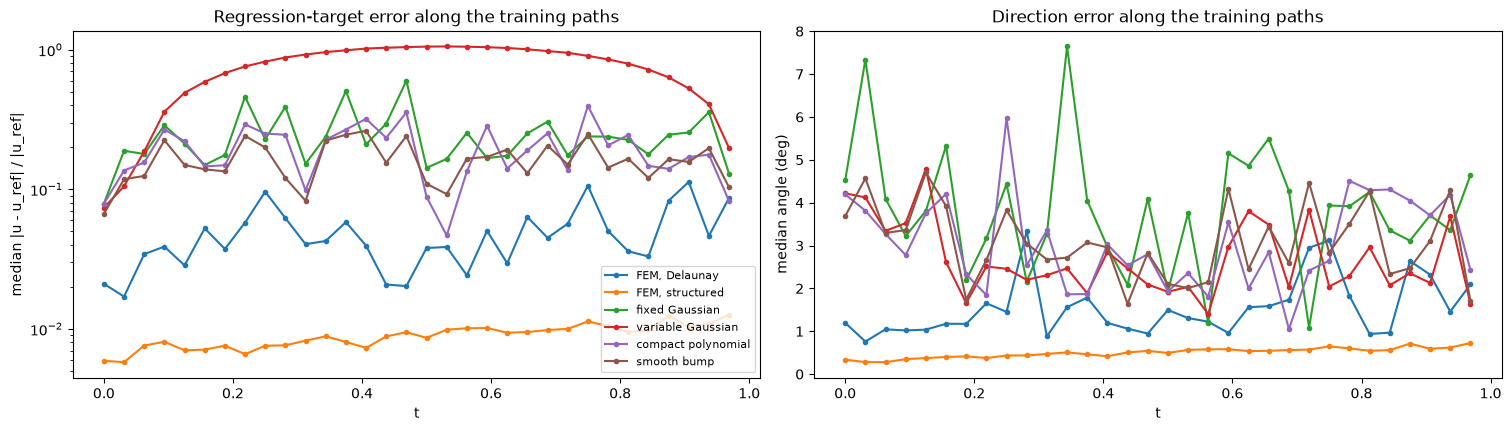

In [17]:
# Regression targets at the reference's 32 training states (fixed grid t_k = k/32, k = 0..31).
ref_times, ref_states, ref_targets = jax.jit(training_interpolator(premetrics["reference"]).trajectory, static_argnums=2)(
    jnp.asarray(x0), jnp.asarray(x1), 32)
flat_t = ref_times.reshape(-1, 1)
flat_x = ref_states.reshape(-1, 2)
flat_x1 = jnp.broadcast_to(jnp.asarray(x1)[None], ref_states.shape).reshape(-1, 2)
flat_ref = np.asarray(ref_targets.reshape(-1, 2), dtype=np.float64)
step_index = np.repeat(np.arange(32), len(x0))

target_rows, target_errors = {}, {}
for name in path_names[1:]:
    u = np.asarray(jax.jit(training_interpolator(premetrics[name]).u_t)(flat_x, flat_x1, flat_t), dtype=np.float64)
    relative = np.linalg.norm(u - flat_ref, axis=1) / np.maximum(np.linalg.norm(flat_ref, axis=1), 1e-12)
    angles = angle_deg(u, flat_ref)
    target_errors[name] = (relative, angles)
    target_rows[name] = {"relative_error_median": np.median(relative), "relative_error_p90": np.quantile(relative, 0.9),
                         "angle_median": np.median(angles), "angle_p90": np.quantile(angles, 0.9),
                         "fraction_angle>30": np.mean(angles > 30),
                         "relative_mse": np.sum((u - flat_ref) ** 2) / np.sum(flat_ref**2)}
display(pd.DataFrame(target_rows).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), constrained_layout=True)
for name, (relative, angles) in target_errors.items():
    axes[0].plot(np.arange(32) / 32, [np.median(relative[step_index == k]) for k in range(32)], marker=".", label=name)
    axes[1].plot(np.arange(32) / 32, [np.median(angles[step_index == k]) for k in range(32)], marker=".", label=name)
axes[0].set(xlabel="t", ylabel="median |u - u_ref| / |u_ref|", yscale="log", title="Regression-target error along the training paths")
axes[1].set(xlabel="t", ylabel="median angle (deg)", title="Direction error along the training paths")
axes[0].legend(fontsize=8)
plt.show()

**Time profile.** How much of the centerline distance to $x_1$ the 512-step paths have covered by time $t$ (median over pairs); a path at constant speed would give $t$.

In [18]:
x1_arc = roll.arc_length(roll.roll_angle(x1))
progress_rows = {}
for name in path_names:
    _, paths = ref_paths[name, 512]
    remaining = np.abs(roll.arc_length(roll.roll_angle(paths)) - x1_arc[:, None])
    progress = 1.0 - remaining / remaining[:, :1]
    progress_rows[name] = {f"t={t}": np.median(progress[:, int(round(t * 512))]) for t in (0.25, 0.5, 0.75, 0.9)}
display(pd.DataFrame(progress_rows).T)

,t=0.25,t=0.5,t=0.75,t=0.9
reference,0.325356,0.542405,0.749413,0.887346
"FEM, Delaunay",0.324933,0.540860,0.747040,0.886182
"FEM, structured",0.325288,0.542332,0.749274,0.887099
fixed Gaussian,0.341210,0.551272,0.761892,0.899515
variable Gaussian,0.479050,0.872421,0.992648,0.999395
compact polynomial,0.325618,0.546113,0.744583,0.887062
smooth bump,0.325450,0.547746,0.746572,0.887545


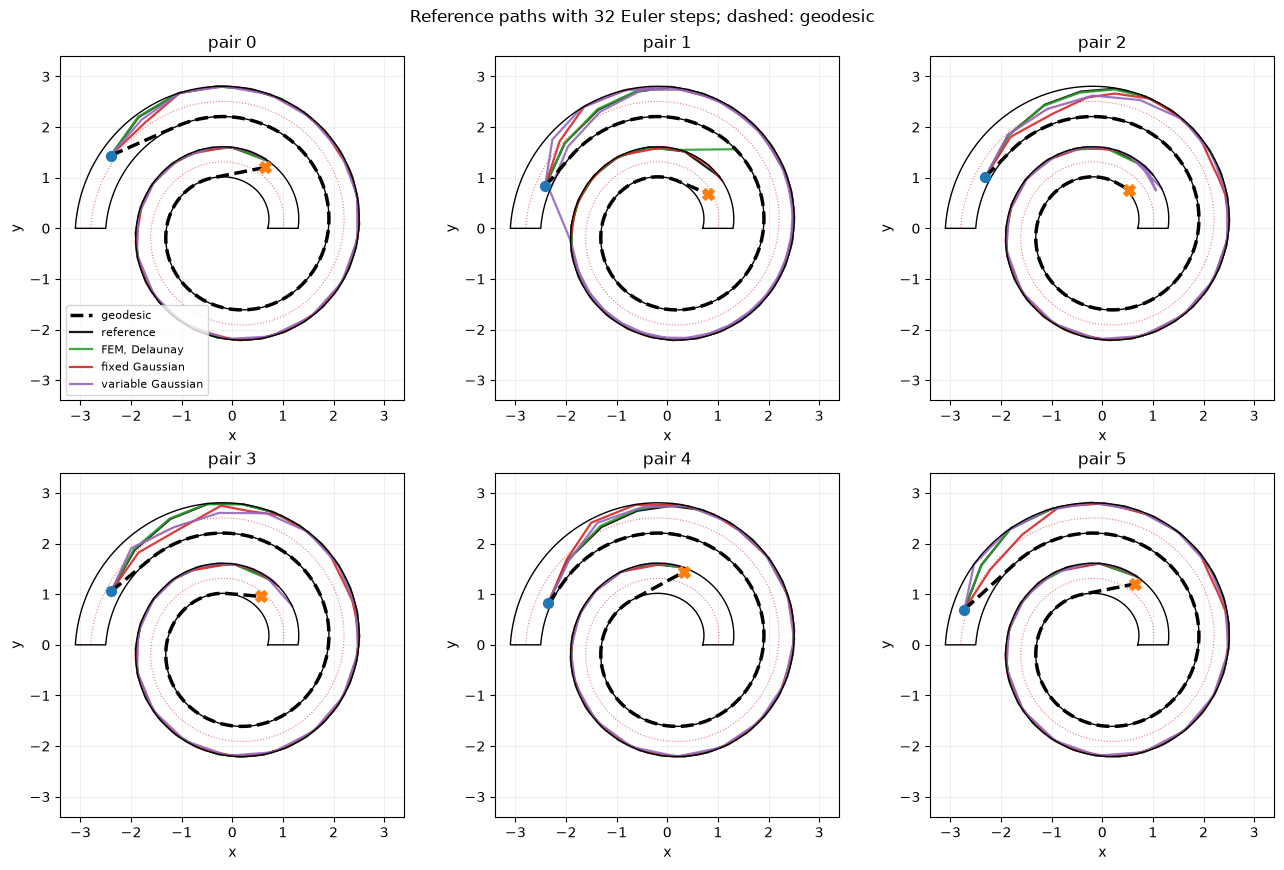

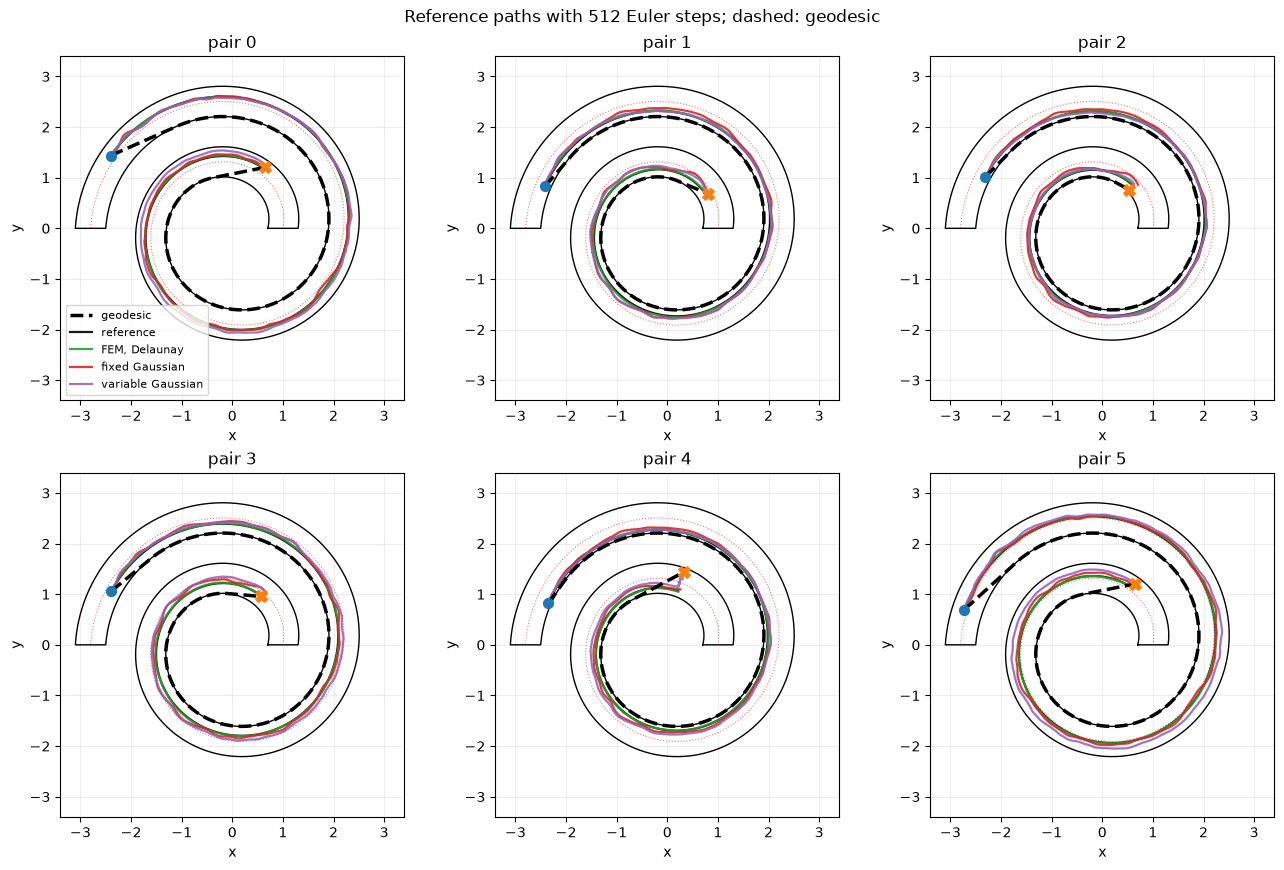

In [19]:
example_names = ["reference", "FEM, Delaunay", "fixed Gaussian", "variable Gaussian"]
example_colors = dict(zip(example_names, ["black", "tab:green", "tab:red", "tab:purple"], strict=True))
for steps in ref_steps:
    reference_paths.plot_reference_paths(
        roll, x0, x1, {name: ref_paths[name, steps][1] for name in example_names}, example_colors,
        np.linspace(0.0, 1.0, 400), np.arange(6), title=f"Reference paths with {steps} Euler steps; dashed: geodesic")

**Reading.**

* **Shapes at 512 steps.** The FEM paths and the reference path are nearly the same: the largest gap is 0.04 (median) for the Delaunay mesh and 0.03 for the structured mesh. They are equally close to the geodesics: Hausdorff 0.31, Chamfer 0.26–0.27, 15% longer than the geodesic.
* **Kernel paths.** Similar shapes (Hausdorff 0.35–0.40), but a different schedule. At the same time t, the fixed Gaussian is up to 0.49 (median) from the reference path, and the variable Gaussian is 3.6 away, a quarter of the roll ahead.
* **Time profile.** The exact operator is front-loaded on its own: 54% of the centerline distance by t = 0.5, and 89% by t = 0.9. FEM and the compact profiles reproduce this to within 0.5 points; the fixed Gaussian runs about 1 point ahead; the variable Gaussian is at 87% by t = 0.5. The front-loading of the RFM marginals noted in the swiss roll notebook is therefore a property of biharmonic RFM.
* **32 training steps.** All premetrics ride the outer edge (Hausdorff ≈ 0.6, the roll width). Fractions of paths that cut across a gap: reference 0%, FEM structured 0.4%, FEM Delaunay 7.4%, fixed Gaussian 9.4%, smooth bump 10.5%, variable Gaussian 22.7%, compact polynomial 28%. The Delaunay crossings all happen on the first or the last Euler step. That step is about 0.9 long (longer than the 0.6 gap) and starts at the edge of the strip, so direction errors of 2.5–20° are enough to land on the neighbouring turn.
* **Regression targets.** At the same states:

  | Premetric | Median relative error | 90th percentile | Median angle | Relative squared error |
  | --- | --- | --- | --- | --- |
  | FEM, Delaunay | 4% | 10% | 1.4° | 0.005 |
  | FEM, structured | 0.9% | — | 0.5° | — |
  | kernel profiles | 15–21% | — | 2.9–3.5° | — |
  | fixed Gaussian | 21% | 52% | 3.5° | 0.09 |
  | variable Gaussian | 87% | — | — | 0.49 |

## 9 · Cost

Fit time (mesh, matrices and eigen-solve, or kernel graph and eigen-solve), and the time of one jitted target-field evaluation on a training-sized batch (32 pairs × 32 states), averaged over 20 calls on the GPU. The Delaunay FEM locates points by brute force over all 9,700 faces, as the reference code does. The structured meshes use an O(1) lookup in strip coordinates, which only exists because the roll has a known parametrization.

In [20]:
batch_x = jnp.asarray(ref_states[:, :32].reshape(-1, 2))
batch_x1 = jnp.broadcast_to(jnp.asarray(x1[:32])[None], ref_states[:, :32].shape).reshape(-1, 2)
batch_t = ref_times[:, :32].reshape(-1, 1)
cost_rows = {}
for name in path_names:
    u_t = jax.jit(training_interpolator(premetrics[name]).u_t)
    u_t(batch_x, batch_x1, batch_t).block_until_ready()
    started = time.perf_counter()
    for _ in range(20):
        u_t(batch_x, batch_x1, batch_t).block_until_ready()
    fit_seconds = fem_fits[name].diagnostics["fit_seconds"] if name in fem_fits else kernel_fit_df.loc[name, "fit_seconds"]
    cost_rows[name] = {"fit_seconds": fit_seconds, "field_ms_per_1024_points": 1000 * (time.perf_counter() - started) / 20}
display(pd.DataFrame(cost_rows).T)

,fit_seconds,field_ms_per_1024_points
reference,16.225406,0.729900
"FEM, Delaunay",0.120973,2.646318
"FEM, structured",0.097876,0.644721
fixed Gaussian,1.423714,1.575182
variable Gaussian,0.567096,1.488472
compact polynomial,0.705034,1.564888
smooth bump,0.676814,1.640792


**Reading.**

* **Fitting** is cheap either way: 0.16 s for FEM on 5,000 vertices, 0.6–2 s for a kernel, and 16 s for the 303k-vertex reference.
* **Evaluating the field** costs 2.6 ms per 1,024 points with the brute-force closest-triangle search of the reference code, against 1.7–1.9 ms for the Nyström extension. An O(1) lookup (structured mesh) brings it to 0.6–0.7 ms.
* **Scaling.** Both brute-force searches grow linearly with the size of the construction set.

## 10 · Training CellFlow RFM with each premetric

Same model, data, OT settings and training settings as the RFM model of the swiss roll notebook: biharmonic entropic OT ($\varepsilon=0.05$) in each premetric's own coordinates, 32 Euler interpolation steps with roll projection, speed clip 30, `loss_mode="final"`, 300 iterations, batch 32, three network seeds. Only the premetric changes. Evaluated as in that notebook:

* endpoints at $t=1$ against the target cloud (squared energy distance, mean-position error, off-roll fractions);
* the learned marginal at $t=0.5$ against the Gaussian travelling along the centerline (the notebook's `TravellingRollGaussian`).

Results are cached in `riemannian_swiss_roll_fem_training_results.json`; delete the file to retrain.

In [21]:
training_names = ["fixed Gaussian", "FEM, Delaunay", "reference"]
training_seeds = [2026, 2027, 2028]
training_settings = {"names": training_names, "seeds": training_seeds, "num_iterations": 300, "batch_size": 32,
                     "ot_epsilon": 0.05, **training_solver_kwargs}
results_path = "riemannian_swiss_roll_fem_training_results.json"
target_key, condition_name = "inner_gaussian", "inner Gaussian"

marginal_family = intermediate.TravellingRollGaussian(roll, source_arc=roll.centerline_length - end_offset,
                                                      target_arc=end_offset, variance=variance)
marginal_reference = marginal_family.sample(0.5, len(source), np.random.default_rng(2026 + 50))

def train_and_evaluate(name, seed):
    premetric = premetrics[name]
    match = flows.make_entropic_match_fn(training_settings["ot_epsilon"], embed=jax.jit(jax.vmap(premetric.extend_point)))
    adata = flows.make_toy_adata(source, target, target_key)
    model = flows.prepare_toy_model(
        adata, "otrfm", target_key, **flows.DEFAULT_ARCHITECTURE, match_fn=match, nystroem=premetric,
        optimizer=optax.adam(1e-3), solver_kwargs={**training_solver_kwargs, "projection_fn": roll.project}, seed=seed)
    losses, seconds = flows.train_timed(model, training_settings["num_iterations"], training_settings["batch_size"])
    predicted = flows.predict_target(model, adata, target_key, condition_name)
    half = intermediate.push_forward({name: model}, source, 0.5)[name]
    half_metrics = intermediate.marginal_metrics(half, marginal_reference, roll)
    return {"premetric": name, "seed": seed, "training_seconds": seconds,
            "loss_last_25": float(np.mean(losses[-25:])),
            **flows.endpoint_metrics(predicted, target, roll),
            **{f"t0.5_{key}": value for key, value in half_metrics.items()},
            "predicted": np.asarray(predicted).tolist(), "half": np.asarray(half).tolist()}

cached = json.load(open(results_path)) if os.path.exists(results_path) else None
if cached is not None and cached["settings"] == training_settings:
    training_runs = cached["runs"]
    print(f"Loaded {len(training_runs)} runs from {results_path}.")
else:
    training_runs = []
    for seed in training_seeds:
        for name in training_names:
            training_runs.append(train_and_evaluate(name, seed))
            run = training_runs[-1]
            print(f"{name}, seed {seed}: {run['training_seconds']:.0f}s, energy distance {run['energy_distance_squared']:.3f}, "
                  f"t=0.5 W2 {run['t0.5_wasserstein_2']:.3f}", flush=True)
            json.dump({"settings": training_settings, "runs": training_runs}, open(results_path, "w"))

Loaded 9 runs from riemannian_swiss_roll_fem_training_results.json.


Unchanged source: {'energy_distance_squared': 5.208941722006151, 'mean_error_to_target': 3.0086069107055664, 'outside_roll_fraction': 0.0, 'between_turns_fraction': 0.0, 'beyond_outer_fraction': 0.0, 'not_on_inner_turn_fraction': 1.0, 'mean_roll_violation': 0.0, 'p95_roll_violation': 0.0}
t=0.5 target arc position: 9.00


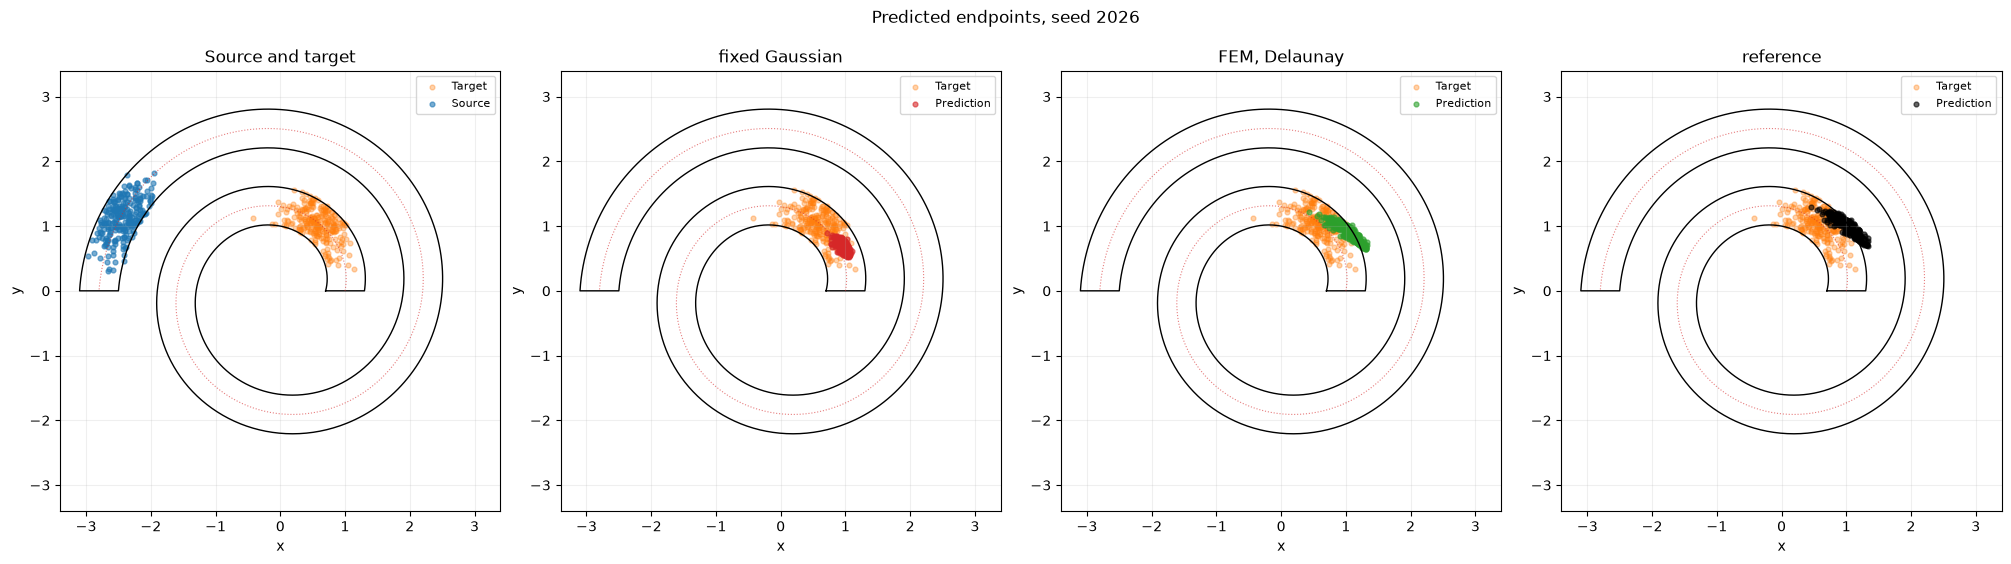

In [22]:
training_df = pd.DataFrame([{k: v for k, v in run.items() if k not in ("predicted", "half")} for run in training_runs])
training_columns = ["energy_distance_squared", "mean_error_to_target", "outside_roll_fraction", "between_turns_fraction",
                    "mean_roll_violation", "t0.5_wasserstein_2", "t0.5_energy_distance_squared", "t0.5_mean_arc_position",
                    "t0.5_outside_roll_fraction", "loss_last_25", "training_seconds"]
training_summary = training_df.groupby("premetric")[training_columns].agg(["mean", "std"]).loc[training_names]
display(training_summary.T.style.format("{:.3f}"))
display(training_df.set_index(["premetric", "seed"])[["energy_distance_squared", "t0.5_wasserstein_2", "t0.5_mean_arc_position"]]
        .unstack("premetric").style.format("{:.3f}"))
print(f"Unchanged source: {flows.endpoint_metrics(source, target, roll)}")
print(f"t=0.5 target arc position: {marginal_family.arc_position(0.5):.2f}")

first_seed = {run["premetric"]: np.asarray(run["predicted"]) for run in training_runs if run["seed"] == training_seeds[0]}
plotting.plot_prediction_panels(roll, source, target, first_seed,
                                dict(zip(training_names, ["tab:red", "tab:green", "black"], strict=True)),
                                title=f"Predicted endpoints, seed {training_seeds[0]}")

**Reading** (3 network seeds per premetric):

* **Endpoints at t = 1.** Squared energy distance is 0.46 ± 0.16 (FEM, Delaunay), 0.48 ± 0.14 (reference) and 0.54 ± 0.06 (fixed Gaussian). The mean-position error is 0.49 for all three. Within seed noise, the premetric does not change the endpoint distribution. One visible difference: the FEM-trained models predict a thin band along the outer edge of the inner turn, and 30% and 43% of their endpoints lie just outside it (mean violation 0.013–0.019). Their 32-step training paths ride that edge. The fixed-Gaussian model predicts a compact cloud inside the roll.
* **Intermediate marginal at t = 0.5.** The FEM-trained models are clearly closer to the travelling Gaussian: W₂ is 0.77 ± 0.04 and 0.82 ± 0.04, against 1.11 ± 0.08. None of their states is off the roll, against 41% for the fixed Gaussian. Mean arc position is 8.2–8.3, against 7.9 (target 9.0).
* **Loss.** The final training loss is 1.3 (FEM, Delaunay) and 0.6 (reference), against 17.9 (fixed Gaussian). The kernel targets carry noise the network cannot fit, consistent with their 21% target error.
* **Run time.** Each run took 20–27 s on the A100, for every premetric.

## 11 · Summary

1. **The training pairs do not depend on the discretization.** Every premetric gives practically the same biharmonic OT coupling: total-variation distance to the reference ≤ 2.4·10⁻⁵, against 0.043 for the Euclidean cost.
2. **FEM on your 5,000 points is the more accurate operator.** Compared with the converged reference, after one global factor:

   | | FEM, Delaunay | best kernel (fixed Gaussian) | other kernels |
   | --- | --- | --- | --- |
   | Spectrum shape error (median / max) | 1.0% / 4.0% | 3.9% / 10.6% | 6.7–8.1% / 12–14% |
   | Distance error (random pairs) | 0.3% | 2.1% | 0.8% |

   A well-shaped mesh of the same size (FEM, structured) is essentially exact: 0.3% spectrum shape error, 0.005% distance error.
3. **The field is where the methods really differ.**
   - FEM fields are within 1° (median) and ±3% speed of the reference.
   - Nyström fields are 3.4–4.8° off (median) and 9–13° (90th percentile), with a speed scatter of roughly −25% to +70%.
   - The variable Gaussian is 4.2× too fast: its truncated kernel turns the extension into a staircase whose jumps the analytic gradient does not see.
   - At the training states, the regression targets are off by 4% (Delaunay FEM, median), 21% (fixed Gaussian) and 87% (variable Gaussian).
4. **The endpoint error at t = 0.99 does not measure accuracy here.** The exact operator stops 0.27 from the target with 32, 64 or 128 modes, because the biharmonic distance on this strip is strongly anisotropic. The kernels get closer only because their fields are too fast. The front-loaded time profile (54% of the way at t = 0.5) is also a property of biharmonic RFM, not of the kernel. *This changes the reading of the kernel section of `riemannian_swiss_roll_toy_example.ipynb`.*
5. **Training (3 seeds).**
   - Endpoints at t = 1 agree within seed noise.
   - The t = 0.5 marginal is clearly better with an FEM premetric: W₂ 0.77–0.82 vs 1.11, and 0% vs 41% of states off the roll.
   - The final regression loss is 14–30× lower with FEM.
   - On the other hand, the FEM-trained models leave 30–43% of their endpoints marginally (about 0.015) outside the edge of the roll.
6. **Limits of FEM.**
   - It needs a mesh. A Delaunay mesh of random samples misses a 4% boundary layer, which pushes the first across-strip mode out of the 32 modes.
   - 7% of its 32-step training paths cross a gap on the long first or last Euler step (0% for the reference, 0.4% for the structured mesh).
   - For cell data, which has no mesh, the kernel graph remains the practical choice. There, a profile that vanishes continuously at the edge of its support (compact polynomial, smooth bump) avoids the staircase bias of the truncated Gaussians.

**Caveats.** libigl's matrices are re-implemented, not called. JAX runs in float32. One target configuration; 3 network seeds for training.